# 02 — Historical experiments and evidence

Eight historical topics connect implementation, saved metrics and the decision made at the time. The original vocabulary study stopped at 8/9 nested folds. The subsequent approved continuation is in [03 — Models and E0–E6](03_Model_Versions_and_Final_Evaluation.ipynb).


## 1. Shared interpretation rules

**Original v3:** 3,849 training rows, 775/951 course-dev correct.
**Cleaned v3 control:** 3,730 training rows, 772/951 course-dev correct.
**Original v4:** 810/951. The later matched cleaned-data v4 control is 809/951.
These controls must not be silently interchanged.

Course dev (951), historical external dev (306), and paired confirmation (200) were repeatedly
inspected. The paired confirmation set is now a reused development panel, not a pristine final test.
The 2,366-record internal external panel in the latest studies is 1,566 legacy-training records
plus 800 paired-training records. It is distinct from the 306- and 200-record dev panels.
A training fit score, cross-validation score, development score, and leaderboard score answer
different questions. No fresh leaderboard result is present here.

In [1]:
import sys
from pathlib import Path
_REPO = Path.cwd().resolve()
if _REPO.name in {"notebooks", "experiments"}:
    _REPO = _REPO.parent
if not (_REPO / "data/manifests/approved_inputs.json").is_file():
    raise RuntimeError("Open from the repository root, notebooks folder, or experiments folder.")
if str(_REPO / "src") not in sys.path:
    sys.path.insert(0, str(_REPO / "src"))
import os
import tempfile
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "dragonthree-mpl"))
os.environ.setdefault("MPLBACKEND", "Agg")
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.base import clone
from sklearn.svm import LinearSVC
from IPython.display import display, Markdown, Code
from dragonthree.project_io import ROOT, READS, load_data, load_result, source_text, source_link, install_data_guard, show_figure
install_data_guard()
EXPERIMENTS = "quality_pipeline/experiments/"
print("Offline evidence review. No search or training is launched.")

def saved_metric_row(study, case, panel, metric):
    return {"study": study, "case": case, "panel": panel, "n": metric["n"],
            "correct": metric["correct"], "accuracy_pct": 100*metric["accuracy"],
            "balanced_accuracy_pct": 100*metric.get("balanced_accuracy",np.nan),
            "macro_f1": metric.get("macro_f1",np.nan), "ROC_AUC": metric.get("roc_auc",np.nan)}

def reference(path):
    """Link to the archived source text; never import it."""
    display(Markdown("Historical implementation: [" + path + "](" + source_link(path) + ")"))

def show_source_function(path, function_name):
    """Display one original function as evidence, without evaluating its code."""
    text = source_text(path)
    tree = ast.parse(text)
    node = next(n for n in tree.body if isinstance(n,(ast.FunctionDef,ast.ClassDef)) and n.name == function_name)
    display(Code(ast.get_source_segment(text,node),language="python"))

Offline evidence review. No search or training is launched.


## 1. Supplementary data collection

Discover public news URL candidates, collect provenance and assemble the supplementary pool.

[Saved evidence](experiments/historical/collection.json)


The collection and curation implementations are in [01 — Data collection and cleaning](01_Data_Collection_and_Cleaning.ipynb#12-archived-collection-and-event-pairing-source).


## 2. External-data weighting

Compare historical and recent external-example weights against a course-only reference.

[Saved evidence](experiments/historical/weight_results.json)


### weight_search.py.txt

<a id="source-quality-pipeline-experiments-external-weight-search-2026-10-27-weight-search-py"></a>

quality_pipeline/experiments/external_weight_search_2026-10-27/weight_search.py

**What this code does.** Compares training weights for external news examples. It prepares features within each validation fold, fits linear classifiers under different weighting settings, and records the comparison.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Training-only, grouped comparison of external-example loss weights for v3.
    
    Final holdout is never parsed, transformed, predicted, or used for selection.
    """
    import os
    for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','VECLIB_MAXIMUM_THREADS'):os.environ[key]='1'
    import argparse,hashlib,json,resource,sys,time
    from pathlib import Path
    import numpy as np
    from scipy import sparse
    from sklearn.svm import LinearSVC
    from sklearn.model_selection import StratifiedGroupKFold
    import torch
    
    HERE=Path(__file__).resolve().parent
    PIPELINE=HERE.parents[1]
    sys.path.insert(0,str(PIPELINE))
    from common import DEFAULT_PROJECT,LABELS,read_csv,write_csv,sha,load_module,metric_values,cluster_ci,normalized
    
    def candidates():
        result=[{'name':'course_only','historical_weight':0.,'recent_weight':0.}]
        for weight in (.01,.025,.05,.1,.25,.5,1.):
            result.append({'name':f'all_{weight:g}','historical_weight':weight,'recent_weight':weight})
        for recent in (.5,1.):
            result.append({'name':f'recent_{recent:g}','historical_weight':0.,'recent_weight':recent})
            for history in (.025,.05,.1):
                result.append({'name':f'history_{history:g}_recent_{recent:g}','historical_weight':history,'recent_weight':recent})
        return result
    
    def get_weights(rows,spec):
        return np.array([1. if r['origin']=='course' else spec['recent_weight'] if r['origin']=='recent_2026' else spec['historical_weight'] for r in rows])
    
    def fit_linear(X,y,weights,seed=42):
        active=weights>0
        clf=LinearSVC(C=4.,dual=True,max_iter=20000,random_state=seed)
        clf.fit(X[active],y[active],sample_weight=weights[active])
        return clf
    
    def prepare_fold(search,rows,train_idx,val_idx):
        # Fit vocabulary and IDF on course training rows only. External loss weight=0
        # then truly has no effect; weight changes do not silently change IDF/vocabulary.
        course=[rows[i]['text'] for i in train_idx if rows[i]['origin']=='course']
        vectors={name:search.make_vectorizer(name) for name in ('word12','char25')}
        for vector in vectors.values():vector.fit(course)
        X=sparse.hstack([v.transform([rows[i]['text'] for i in train_idx]) for v in vectors.values()],format='csr')
        V=sparse.hstack([v.transform([rows[i]['text'] for i in val_idx]) for v in vectors.values()],format='csr')
        return vectors,X,V
    
    def prepare_joint_fold(search,rows,train_idx,val_idx):
        """Alternate ablation: vocabulary/IDF fitted on all allowed training-fold texts.
    
        Loss weights still apply only to the classifier. This intentionally isolates
        representation adaptation from label-weight effects; it is not weighted IDF.
        """
        texts=[rows[i]['text'] for i in train_idx]
        vectors={name:search.make_vectorizer(name) for name in ('word12','char25')}
        X=sparse.hstack([v.fit_transform(texts) for v in vectors.values()],format='csr')
        V=sparse.hstack([v.transform([rows[i]['text'] for i in val_idx]) for v in vectors.values()],format='csr')
        return vectors,X,V
    
    def main():
        parser=argparse.ArgumentParser(description=__doc__)
        parser.add_argument('--project-dir',type=Path,default=DEFAULT_PROJECT)
        parser.add_argument('--cpu-seconds',type=int,default=420)
        parser.add_argument('--representation',choices=['course','joint'],default='course')
        parser.add_argument('--out',type=Path,default=None)
        args=parser.parse_args();project=args.project_dir
        global HERE
        if args.out is not None:HERE=args.out.resolve();HERE.mkdir(parents=True,exist_ok=True)
        resource.setrlimit(resource.RLIMIT_CPU,(args.cpu_seconds,args.cpu_seconds+5));torch.set_num_threads(1)
        sys.path.insert(0,str(project/'DragonThree_v3'))
        search=load_module(project/'DragonThree_v3/search.py','weight_v3_search')
        exporter=load_module(project/'DragonThree_v3/train_export.py','weight_v3_export')
        pp=load_module(project/'DragonThree_v3/preprocess.py','weight_preprocess')
        rows=read_csv(PIPELINE/'training/training_metadata.csv')
        known_manifest=json.loads((PIPELINE/'training/training_manifest.json').read_text())
        assert sha(PIPELINE/'training/cleaned_augmented_train_urls.csv')==known_manifest['contracts']['cleaned_augmented_train']['train_sha256']
        allowed=[r['url'] for r in read_csv(PIPELINE/'training/cleaned_augmented_train_urls.csv')]
        assert [r['url'] for r in rows]==allowed
        for r in rows:assert pp.url_to_text(r['url'])==r['text'] and pp.label_from_url(r['url'])==r['label']
        y=np.array([LABELS.index(r['label']) for r in rows]);groups=np.array([r['cv_group'] for r in rows])
        is_course=np.array([r['origin']=='course' for r in rows])
        cases=candidates();seeds=[5190,5191,5192]
        if args.representation=='joint':cases.insert(1,{'name':'vocabulary_only','historical_weight':0.,'recent_weight':0.})
        old_recipe=json.loads((project/'DragonThree_v3/results/selection.json').read_text())['selected_recipe']
        assert old_recipe['members']==['short_char']
        scale=old_recipe['scales']['short_char'];threshold=old_recipe['threshold']
        lock=json.loads((PIPELINE/'TRAINING_PROTOCOL.json').read_text())['final_holdout_sha256']
        assert sha(PIPELINE/'data/external_holdout_urls.csv')==lock
        plan={'created_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime()),'cases':cases,'fold_seeds':seeds,
            'folds_per_seed':3,'primary_selection_metric':'mean course-only OOF accuracy across three group partitions',
            'tie_break':'smaller total external sample weight, then candidate name',
            'v3_fixed_recipe':old_recipe,'representation':args.representation,
            'representation_details':'word12 + char25; course baseline always fitted on course training fold only; joint mode fits other cases on all allowed training-fold texts',
            'weighting':'course sample weight=1; loss weights applied via LinearSVC.sample_weight; zero-weight rows excluded from fitting',
            'cv_effective_gate':'course mean gain >=0.002, positive course gain on at least 2 of 3 seeds, and external OOF mean >= baseline',
            'development_gate':'chosen candidate course-dev correct >= original v3 (775/951) AND >= matched zero-weight baseline, and external-dev correct > matched baseline',
            'dev_policy':'Only the training-CV-selected nonzero candidate and matched zero baseline are evaluated; no runner-up dev search',
            'v4_policy':'transfer only if CV and development gates pass; final test never evaluated',
            'cpu_limit_seconds':args.cpu_seconds,'final_holdout_sha256':lock,
            'inputs':{str(p.relative_to(PIPELINE)):sha(p) for p in [PIPELINE/'training/training_metadata.csv',PIPELINE/'training/cleaned_augmented_train_urls.csv',PIPELINE/'data/external_dev_urls.csv']}}
        (HERE/'preregistered_plan.json').write_text(json.dumps(plan,indent=2)+'\n')
        scores=np.zeros((len(seeds),len(cases),len(rows)));fold_logs=[];start_cpu=time.process_time()
        for si,seed in enumerate(seeds):
            splitter=StratifiedGroupKFold(3,shuffle=True,random_state=seed)
            for fold,(tr,va) in enumerate(splitter.split(np.zeros(len(rows)),y,groups)):
                assert not set(groups[tr])&set(groups[va])
                vectors,X,V=prepare_fold(search,rows,tr,va);training=[rows[i] for i in tr]
                if args.representation=='joint':joint_vectors,joint_X,joint_V=prepare_joint_fold(search,rows,tr,va)
                for ci,case in enumerate(cases):
                    a,b=(joint_X,joint_V) if args.representation=='joint' and case['name']!='course_only' else (X,V)
                    clf=fit_linear(a,y[tr],get_weights(training,case))
                    margin=clf.decision_function(b)/scale-threshold;scores[si,ci,va]=margin
                    for scope,mask in [('course',is_course[va]),('external',~is_course[va])]:
                        fold_logs.append({'seed':seed,'fold':fold,'case':case['name'],'scope':scope,'n':int(mask.sum()),'accuracy':float(np.mean((margin[mask]>0)==y[va][mask]))})
                print(json.dumps({'seed':seed,'fold':fold,'candidates_finished':len(cases),'cpu_seconds':time.process_time()-start_cpu}),flush=True)
        ranking=[];correct=scores>0
        for ci,case in enumerate(cases):
            course_acc=np.mean(correct[:,ci,is_course]==y[is_course],axis=1)
            ext_acc=np.mean(correct[:,ci,~is_course]==y[~is_course],axis=1)
            delta=course_acc-np.mean(correct[:,0,is_course]==y[is_course],axis=1)
            paired=(correct[:,ci,is_course]==y[is_course]).mean(0)-(correct[:,0,is_course]==y[is_course]).mean(0)
            ci95=cluster_ci(paired,groups[is_course].tolist(),draws=2000)
            total=float(get_weights(rows,case)[~is_course].sum())
            ranking.append({**case,'course_cv_mean':float(course_acc.mean()),'course_cv_by_seed':course_acc.tolist(),'external_cv_mean':float(ext_acc.mean()),
                'course_delta_by_seed':delta.tolist(),'course_delta_mean':float(delta.mean()),'paired_cluster_delta_95':ci95,
                'total_external_weight':total,'effective_external_weight_fraction':total/(is_course.sum()+total),
                'cv_gate_passed':bool(delta.mean()>=.002 and (delta>0).sum()>=2 and ext_acc.mean()>=np.mean(correct[:,0,~is_course]==y[~is_course]))})
        ranking.sort(key=lambda r:(-r['course_cv_mean'],r['total_external_weight'],r['name']))
        nonzero=next(r for r in ranking if r['name']!='course_only')
        result={'ranking':ranking,'overall_cv_winner':ranking[0]['name'],'selected_nonzero_candidate':nonzero,'development_selection_used':False,
            'final_holdout_evaluated':False,'cv_cpu_seconds':time.process_time()-start_cpu}
        (HERE/'cv_selection.json').write_text(json.dumps(result,indent=2)+'\n')
        write_csv(HERE/'cv_fold_results.csv',fold_logs,list(fold_logs[0]))
        write_csv(HERE/'weight_comparison.csv',ranking,['name','historical_weight','recent_weight','course_cv_mean','external_cv_mean','course_delta_mean','total_external_weight','effective_external_weight_fraction','cv_gate_passed'])
        np.savez_compressed(HERE/'training_oof.npz',scores=scores,y=y,groups=groups,is_course=is_course,cases=np.array([c['name'] for c in cases]),seeds=seeds)
        print('CV selection: '+json.dumps(result),flush=True)
        # Commit the selection file before loading development labels or fitting final artifacts.
        cases_to_check=[cases[0],next(c for c in cases if c['name']==nonzero['name'])]
        development=[('course_dev',project/'baseline/data/val.csv'),('external_dev',PIPELINE/'data/external_dev_urls.csv')]
        datasets={}
        for label,path in development:
            texts,names=pp.prepare_data(str(path));url=[r['url'] for r in read_csv(path)]
            assert not set(url)&set(allowed)
            datasets[label]=(texts,np.array([LABELS.index(n) for n in names]),url)
        metrics=[];predictions=[]
        for case in cases_to_check:
            builder=prepare_joint_fold if args.representation=='joint' and case['name']!='course_only' else prepare_fold
            vectors,X,_=builder(search,rows,np.arange(len(rows)),np.array([0]))
            clf=fit_linear(X,y,get_weights(rows,case));offset=0;weights={}
            for name,vector in vectors.items():
                size=len(vector.vocabulary_);weights[name]=clf.coef_[0][offset:offset+size]/scale;offset+=size
            bias=float(clf.intercept_[0])/scale-threshold
            model,_=exporter.export(vectors,weights,bias,HERE/'v3'/case['name'])
            checks={}
            for split,(texts,truth,urls) in datasets.items():
                matrix=sparse.hstack([v.transform(texts) for v in vectors.values()],format='csr')
                expected=clf.decision_function(matrix)/scale-threshold;actual=model.decision_function(texts)
                np.testing.assert_allclose(expected,actual,atol=1e-9,rtol=1e-9)
                pred=(actual>0).astype(int);checks[split]=metric_values(truth,pred,actual)
                for url,t,a,z,s in zip(urls,texts,truth,pred,actual):predictions.append({'candidate':case['name'],'dataset':split,'url':url,'model_text':t,'actual':LABELS[a],'prediction':LABELS[z],'margin_nbc':float(s)})
            metrics.append({'case':case,'metrics':checks,'checkpoint_sha256':sha(HERE/'v3'/case['name']/'model.pt'),'export_parity':'PASS'})
            print('Development: '+json.dumps(metrics[-1]),flush=True)
        base,new=metrics
        dev_gate=(new['metrics']['course_dev']['correct']>=max(775,base['metrics']['course_dev']['correct']) and new['metrics']['external_dev']['correct']>base['metrics']['external_dev']['correct'])
        outcome={'cv_selection':result,'v3_development':metrics,'cv_gate_passed':nonzero['cv_gate_passed'],'dev_gate_passed':bool(dev_gate),
            'apply_to_v4':bool(nonzero['cv_gate_passed'] and dev_gate),'final_holdout_evaluated':False,
            'final_holdout_hash_unchanged':sha(PIPELINE/'data/external_holdout_urls.csv')==lock,'cpu_seconds':time.process_time()-start_cpu}
        (HERE/'v3_results.json').write_text(json.dumps(outcome,indent=2)+'\n')
        write_csv(HERE/'v3_development_predictions.csv',predictions,list(predictions[0]))
        print('Transfer to v4: '+str(outcome['apply_to_v4']),flush=True)
    
    if __name__=='__main__':main()


### External sample-weight search

**Question:** does downweighting old external examples preserve course performance?
Sixteen fixed-vocabulary configurations considered all/recent/history weights, including
0, .01, .025, .05, .1, .25, .5, and 1; a second 17-case study changed vocabulary fitting.
The exact combinations, rather than a Cartesian product of these values, appear below.
Fits used training-only grouped folds. The clean course control retained the original v3 recipe.
Neither study passed the gate for applying the approach to v4.

In [2]:
weight = load_result("weight_results")
joint = load_result("weight_joint")
for title, result in [("Course vocabulary",weight),("Joint vocabulary",joint)]:
    ranking = pd.DataFrame(result["cv_selection"]["ranking"])
    print(title, "configurations:",len(ranking))
    display(ranking[["name","historical_weight","recent_weight","course_cv_mean",
                     "external_cv_mean","course_delta_mean","cv_gate_passed"]])
weight_dev = []
for title,result in [("fixed vocabulary",weight),("joint vocabulary",joint)]:
    for case in result["v3_development"]:
        for panel,m in case["metrics"].items():
            weight_dev.append(saved_metric_row(title,case["case"]["name"],panel,m))
display(pd.DataFrame(weight_dev))
reference(EXPERIMENTS+"external_weight_search_2026-10-27/weight_search.py")

Course vocabulary configurations: 16


,name,historical_weight,recent_weight,course_cv_mean,external_cv_mean,course_delta_mean,cv_gate_passed
0,course_only,0.000,0.000,0.791421,0.452533,0.000000,False
1,recent_1,0.000,1.000,0.790617,0.456364,-0.000804,False
2,recent_0.5,0.000,0.500,0.790527,0.456152,-0.000894,False
3,all_0.01,0.010,0.010,0.789455,0.489357,-0.001966,False
4,all_0.025,0.025,0.025,0.784182,0.533418,-0.007239,False
5,history_0.025_recent_0.5,0.025,0.500,0.782484,0.534270,-0.008937,False
6,history_0.025_recent_1,0.025,1.000,0.782395,0.534057,-0.009026,False
7,all_0.05,0.050,0.050,0.773101,0.568753,-0.018320,False
8,history_0.05_recent_1,0.050,1.000,0.771492,0.568327,-0.019929,False
9,history_0.05_recent_0.5,0.050,0.500,0.771046,0.568966,-0.020375,False


Joint vocabulary configurations: 17


,name,historical_weight,recent_weight,course_cv_mean,external_cv_mean,course_delta_mean,cv_gate_passed
0,course_only,0.000,0.000,0.791421,0.452533,0.000000,False
1,recent_0.5,0.000,0.500,0.789991,0.455726,-0.001430,False
2,recent_1,0.000,1.000,0.789812,0.456790,-0.001609,False
3,vocabulary_only,0.000,0.000,0.789723,0.448702,-0.001698,False
4,all_0.01,0.010,0.010,0.789723,0.478714,-0.001698,False
5,all_0.025,0.025,0.025,0.787399,0.509579,-0.004021,False
6,history_0.025_recent_0.5,0.025,0.500,0.787221,0.506811,-0.004200,False
7,history_0.025_recent_1,0.025,1.000,0.787221,0.507876,-0.004200,False
8,history_0.05_recent_0.5,0.050,0.500,0.782038,0.531290,-0.009383,False
9,history_0.05_recent_1,0.050,1.000,0.782038,0.531716,-0.009383,False


,study,case,panel,n,correct,accuracy_pct,balanced_accuracy_pct,macro_f1,ROC_AUC
0,fixed vocabulary,course_only,course_dev,951,772,81.177708,81.174259,0.811564,0.887320
1,fixed vocabulary,course_only,external_dev,306,129,42.156863,42.156863,0.415571,0.410483
2,fixed vocabulary,recent_1,course_dev,951,771,81.072555,81.069881,0.810595,0.888408
3,fixed vocabulary,recent_1,external_dev,306,137,44.771242,44.771242,0.442707,0.416635
4,joint vocabulary,course_only,course_dev,951,772,81.177708,81.174259,0.811564,0.887320
5,joint vocabulary,course_only,external_dev,306,129,42.156863,42.156863,0.415571,0.410483
6,joint vocabulary,recent_0.5,course_dev,951,771,81.072555,81.069659,0.810573,0.888173
7,joint vocabulary,recent_0.5,external_dev,306,133,43.464052,43.464052,0.428778,0.406510


Historical implementation: [quality_pipeline/experiments/external_weight_search_2026-10-27/weight_search.py](source_archive/quality_pipeline/experiments/external_weight_search_2026-10-27/weight_search.py.txt)

## 3. Short-input emphasis

Test whether changing training weights for short headlines helps compared with a matched reference.

[Saved evidence](experiments/historical/factor_results.json)


### study.py.txt

<a id="source-quality-pipeline-experiments-factor-ablation-v4-2026-10-29-study-py"></a>

quality_pipeline/experiments/factor_ablation_v4_2026-10-29/study.py

**What this code does.** Tests whether emphasizing short inputs helps V4. It reuses cached features, adjusts example weights, fits comparison models, and summarizes score changes and uncertainty.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Training-only factor study, locked selection, then descriptive development audit."""
    from support import *
    import copy,gc,resource
    from collections import Counter,defaultdict
    import numpy as np,torch
    from scipy import sparse
    from scipy.optimize import linear_sum_assignment
    from sklearn.model_selection import KFold
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    torch.set_num_threads(1)
    resource.setrlimit(resource.RLIMIT_CPU,(1800,1803))
    sys.path.insert(0,str(PROJECT/'DragonThree_v4'))
    adv=load(PROJECT/'DragonThree_v4/advanced_search.py','factor_advanced')
    exp=load(PROJECT/'DragonThree_v4/export.py','factor_export')
    sys.path.insert(0,str(PIPE))
    from common import metric_values
    BASE=PIPE/'experiments/masking_styledistance_2026-10-28/v4_transfer/baseline_model'
    rt=load(BASE/'model.py','factor_runtime')
    pp=load(BASE/'preprocess.py','factor_preprocess')
    recipe=json.loads((PREV/'preregistered_plan.json').read_text())['recipe']
    course=[r for r in read(PIPE/'training/training_metadata.csv') if r['origin']=='course']
    paired=read(PREV/'paired_train.csv')
    ctx=[r['text'] for r in course];etx=[r['text'] for r in paired];texts=ctx+etx
    y=np.array([r['label']=='NBC' for r in course],int)
    ey=np.array([r['publisher']=='NBC' for r in paired],int)
    short=np.array([len(t.split())<=8 for t in etx]);eg=np.array([r['event_group'] for r in paired])
    base=exp.load_bundle(BASE);base._decode()
    
    def balancing(tx,yy):
        bins=np.array([0 if len(t.split())<=5 else 1 if len(t.split())<=8 else 2 if len(t.split())<=12 else 3 for t in tx]);w=np.ones(len(tx))
        for label in (0,1):
            for b in range(4):
                ix=(yy==label)&(bins==b)
                if ix.sum():w[ix]=np.clip(np.sqrt(np.mean(bins==b)/np.mean(bins[yy==label]==b)),.75,1.5)
            w[yy==label]/=w[yy==label].mean()
        return w
    
    def cached_features(fold):
        name=f'fold{fold}_features.npz' if fold is not None else 'full_features.npz'
        z=np.load(PREV/'head_results'/name)
        assert z['digest'].item()==hashlib.sha256('\n'.join(texts).encode()).hexdigest()
        return z['X']
    
    def models_for(fold):
        if fold is None:return list(base.semantic)
        models=[]
        for seed in recipe['neural_seeds']:
            m=rt.SemanticClassifier();m.load_state_dict(torch.load(PREV/'fold_encoders'/f'fold{fold}_seed{seed}.pt',map_location='cpu',weights_only=True));m.eval();models.append(m)
        return models
    
    @torch.inference_mode()
    def embed(models,tx):
        result=[]
        for m in models:
            parts=[]
            for i in range(0,len(tx),64):
                ids,mask=base._tokenizer.batch(tx[i:i+64]);h=m.encoder(ids,mask)
                E=(h*mask.unsqueeze(-1)).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
                parts.append(torch.nn.functional.normalize(E,p=2,dim=1).numpy())
            result.append(np.concatenate(parts).astype(float))
        return np.stack(result)
    
    def matrices(tr,tx=texts):
        vec={n:adv.make_vectorizer(n) for n in ('word12','char25')}
        for v in vec.values():v.fit([ctx[i] for i in tr])
        X=sparse.hstack([v.transform(tx) for v in vec.values()],format='csr')
        sc=StandardScaler().fit(adv.numeric_features([ctx[i] for i in tr]));N=adv.numeric_features(tx)
        return [adv.matrix(X,N,sc,item['spec']) for item in recipe['members']],vec,sc
    
    def external_weights(er,factor,w):
        weights=np.ones(len(er));mask=(ey[er]==0)&short[er];weights[mask]*=factor
        for label in (0,1):
            ix=ey[er]==label
            assert weights[ix].sum()>0
            weights[ix]*=ix.sum()/weights[ix].sum()
        return weights*w
    
    def fit(tr,er,A,E,models,config):
        er=np.asarray(er,dtype=int)
        balanced=config.get('balanced',True)
        weights=balancing([ctx[i] for i in tr],y[tr]) if balanced else np.ones(len(tr))
        w=config.get('weight',0)
        inds=np.r_[tr,len(ctx)+er] if w else tr
        labels=np.r_[y[tr],ey[er]] if w else y[tr]
        weights=np.r_[weights,external_weights(er,config.get('short_factor',1),w)] if w else weights
        fitted=[]
        for matrix,item in zip(A,recipe['members']):
            fitted.append(adv.classifier(item['spec']).fit(matrix[inds],labels,sample_weight=weights))
        heads=[]
        for k,m in enumerate(models):
            oldw=m.head.weight.detach().numpy()[0];oldb=m.head.bias.item()
            if config['name']=='baseline':heads.append((oldw,oldb));continue
            h=LogisticRegression(C=10,solver='liblinear',max_iter=3000,random_state=42).fit(E[k,inds],labels,sample_weight=weights)
            scale=np.std(E[k,tr]@oldw+oldb)/max(np.std(E[k,tr]@h.coef_[0]+h.intercept_[0]),1e-8)
            heads.append((h.coef_[0]*scale,float(h.intercept_[0])*scale))
        return fitted,heads
    
    def score(fitted,heads,A,E,ix):
        sp=np.mean([clf.decision_function(X[ix])/item['score_scale'] for clf,X,item in zip(fitted,A,recipe['members'])],axis=0)
        ne=np.mean([E[k,ix]@w+b for k,(w,b) in enumerate(heads)],axis=0)
        return .75*sp+.25*ne/recipe['neural_scale']-recipe['threshold']
    
    def pairing_subset(er,seed):
        rng=np.random.default_rng(seed);bygroup=defaultdict(dict)
        for i in er:bygroup[eg[i]][int(ey[i])]=int(i)
        strata=defaultdict(list)
        for group,rows in bygroup.items():
            assert set(rows)=={0,1}
            f=paired[rows[0]];strata[(f['topic'],f['published_at'][:7])].append(group)
        matched=[];independent=[];details=[]
        for key,groups in sorted(strata.items()):
            groups=sorted(groups);rng.shuffle(groups);k=int(len(groups)*.4)
            if k==0:continue
            chosen=groups[:k];remaining=groups[k:]
            target=np.array([int(paired[bygroup[g][1]]['words']) for g in chosen])
            pool=np.array([int(paired[bygroup[g][1]]['words']) for g in remaining])
            ri,ci=linear_sum_assignment(abs(target[:,None]-pool[None,:])+rng.uniform(0,.01,(k,len(pool))))
            replacement=[remaining[j] for j in ci]
            fox=[bygroup[g][0] for g in chosen];nbc=[bygroup[g][1] for g in chosen];unpaired=[bygroup[g][1] for g in replacement]
            matched+=fox+nbc;independent+=fox+unpaired
            details.append({'topic':key[0],'month':key[1],'per_publisher':k,'mean_nbc_word_difference':float(np.mean(abs(target-pool[ci])))})
        assert len(matched)==len(independent)
        assert {i for i in matched if ey[i]==0}=={i for i in independent if ey[i]==0}
        assert not {eg[i] for i in independent if ey[i]==0}&{eg[i] for i in independent if ey[i]==1}
        return np.array(sorted(matched)),np.array(sorted(independent)),details
    
    def ci(diff,groups):
        unique,inv=np.unique(groups,return_inverse=True);counts=np.bincount(inv);sums=np.bincount(inv,weights=diff)
        rng=np.random.default_rng(5190);ix=rng.integers(len(unique),size=(2000,len(unique)))
        return np.quantile(sums[ix].sum(1)/counts[ix].sum(1),[.025,.975]).tolist()
    
    def metrics(c,e):
        m=(ey==0)&short
        return {'course_accuracy':float(np.mean((c>0)==y)),'paired_accuracy':float(np.mean((e>0)==ey)),
         'paired_short_fox_recall':float(np.mean(e[m]<=0)),'paired_short_fox_n':int(m.sum())}
    
    cases=[{'name':'baseline','balanced':False,'weight':0},
     {'name':'refit_course_plain','balanced':False,'weight':0},
     {'name':'refit_course_balanced','balanced':True,'weight':0}]
    for factor in (0,1,2,4):
        for w in (.1,.25,1.):cases.append({'name':f'short{factor}_w{w}','short_factor':factor,'weight':w,'balanced':True})
    
    def main():
        if (ROOT/'selection.json').exists():raise RuntimeError('Selection already locked: no rerun/reselection.')
        plan={'purpose':'Separate event-matched collection, short-Fox emphasis and total external training weight.',
         'primary_cases':cases,'fixed_semantic_weight':.25,'fixed_threshold':recipe['threshold'],'course_folds':'Reuse previously fitted fold-local encoders and exact indices; never full-course encoder for OOF.',
         'pairing_ablation':'3 fixed sampling seeds. Within training fold topic x Fox publication month strata choose 40% of events. Identical Fox rows; NBC from corresponding events versus disjoint events matched on topic/month and approximately words. Same rows per outlet. Evaluation always event-disjoint.',
         'pairing_caveat':'Compares collection composition, not a pairwise objective. Unpaired arm covers more distinct events; NBC authors/wire/content cannot all be held constant. Renaming/shuffling pair IDs alone has no effect on this independent-row loss.',
         'short_ablation':'Multiply <=8-word external Fox weights by 0/1/2/4, renormalize within each outlet to preserve total external loss mass. NBC rows unchanged. No synthetic truncation. Topic/byline mix of effective Fox weights can change.',
         'selection':'Among full-pool candidates with course OOF >= baseline-.005, paired OOF >= previous short1_w0.25 and short-Fox recall >= previous, maximize paired OOF then course accuracy then smaller weight and factor. Fallback previous. Pairing subsets diagnostic only.',
         'development':'Only locked candidate and prior models evaluated. Course951, old external306, paired200 all previously inspected development sets, not untouched tests. No development runner-up or threshold search.',
         'protected_models':json.loads((PREV/'preregistered_plan.json').read_text())['protected_models'],
         'input_hashes':{str(p):sha(p) for p in (PIPE/'training/training_metadata.csv',PREV/'paired_train.csv')},
         'final_test_accessed':False}
        dump(ROOT/'preregistered_plan.json',plan)
        C=np.full((len(cases),len(ctx)),np.nan);P=np.full((len(cases),len(etx)),np.nan)
        PC=np.full((3,2,len(ctx)),np.nan);PE=np.full((3,2,len(etx)),np.nan)
        groupnames=sorted(set(eg));splits=list(KFold(3,shuffle=True,random_state=5190).split(groupnames))
        logs=[];sampling=[]
        for fold in range(3):
            start=time.process_time();z=np.load(PREV/'fold_encoders'/f'indices_{fold}.npz');tr,va=z['train'],z['validation']
            et,ev=splits[fold];er=np.flatnonzero(np.isin(eg,[groupnames[i] for i in et]));eva=np.flatnonzero(np.isin(eg,[groupnames[i] for i in ev]))
            assert not set(eg[er])&set(eg[eva])
            assert not {course[i]['cv_group'] for i in tr}&{course[i]['cv_group'] for i in va}
            E=cached_features(fold);models=models_for(fold);A,vec,sc=matrices(tr)
            for j,config in enumerate(cases):
                fits,heads=fit(tr,er,A,E,models,config);C[j,va]=score(fits,heads,A,E,va);P[j,eva]=score(fits,heads,A,E,len(ctx)+eva)
            for repeat,seed in enumerate((5190,5191,5192)):
                matched,independent,detail=pairing_subset(er,seed)
                for arm,subset in enumerate((matched,independent)):
                    fits,heads=fit(tr,subset,A,E,models,{'name':'pairing','weight':.25,'short_factor':1})
                    PC[repeat,arm,va]=score(fits,heads,A,E,va);PE[repeat,arm,eva]=score(fits,heads,A,E,len(ctx)+eva)
                    sampling.append({'fold':fold,'seed':seed,'arm':'matched' if arm==0 else 'unpaired','indices':subset.tolist(),'articles':len(subset),'short_fox':int(np.sum((ey[subset]==0)&short[subset])),'strata':detail})
            logs.append({'fold':fold,'cpu_seconds':time.process_time()-start});print('FOLD_DONE',json.dumps(logs[-1]),flush=True)
            del E,models,A,fits,heads;gc.collect()
        assert all(np.isfinite(x).all() for x in (C,P,PC,PE))
        prior=np.load(PREV/'head_results/training_oof.npz');prioridx=next(i for i,c in enumerate(cases) if c['name']=='short1_w0.25')
        np.testing.assert_allclose(C[0],prior['course_scores'][0],atol=1e-6)
        np.testing.assert_allclose(P[0],prior['paired_scores'][0],atol=1e-6)
        np.testing.assert_allclose(C[prioridx],prior['course_scores'][8],atol=1e-6)
        np.testing.assert_allclose(P[prioridx],prior['paired_scores'][8],atol=1e-6)
        ranking=[{**config,**metrics(C[j],P[j]),'index':j} for j,config in enumerate(cases)]
        previous=ranking[prioridx];baseline=ranking[0]
        eligible=[r for r in ranking if r.get('weight',0)>0 and r['course_accuracy']>=baseline['course_accuracy']-.005 and r['paired_accuracy']>=previous['paired_accuracy'] and r['paired_short_fox_recall']>=previous['paired_short_fox_recall']]
        chosen=sorted(eligible,key=lambda r:(-r['paired_accuracy'],-r['course_accuracy'],r['weight'],r['short_factor']))[0] if eligible else previous
        dump(ROOT/'selection.json',{'selected':chosen,'previous':previous,'ranking':ranking,'development_used_for_selection':False})
        np.savez_compressed(ROOT/'training_oof.npz',C=C,P=P,PC=PC,PE=PE,y=y,ey=ey,short=short,groups=eg)
        dump(ROOT/'sampling_manifest.json',sampling)
        cg=[r['cv_group'] for r in course];contrasts=[]
        def contrast(name,ca,cb,ea,eb):
            cd=((ca>0)==y).astype(float)-((cb>0)==y);ed=((ea>0)==ey).astype(float)-((eb>0)==ey);mask=(ey==0)&short
            return {'contrast':name,'course_delta':float(cd.mean()),'course_ci95':ci(cd,cg),'paired_delta':float(ed.mean()),'paired_ci95':ci(ed,eg),'short_fox_delta':float(ed[mask].mean()),'short_fox_ci95':ci(ed[mask],eg[mask])}
        for j,c in enumerate(cases):
            contrasts.append(contrast(c['name']+' minus previous',C[j],C[prioridx],P[j],P[prioridx]))
        pairresults=[]
        for r in range(3):
            pairresults.append({'seed':5190+r,'matched':metrics(PC[r,0],PE[r,0]),'unpaired':metrics(PC[r,1],PE[r,1]),**contrast('matched minus unpaired',PC[r,0],PC[r,1],PE[r,0],PE[r,1])})
        dump(ROOT/'training_results.json',{'ranking':ranking,'contrasts_vs_previous':contrasts,'pairing_repeats':pairresults,'folds':logs,'prior_oof_reproduction_passed':True,'confidence_intervals':'Event/bootstrap within fixed folds; exploratory, not adjusted for search or overlapping repeats.'})
        print('LOCKED_SELECTION',json.dumps(chosen),flush=True)
        # No development evaluation above this line.
        E=cached_features(None);models=models_for(None);A,vec,sc=matrices(np.arange(len(ctx)))
        fits,heads=fit(np.arange(len(ctx)),np.arange(len(etx)),A,E,models,chosen)
        states=[]
        for k,m in enumerate(models):
            state={n:v.detach().clone() for n,v in m.state_dict().items()};w,b=heads[k]
            state['head.weight']=torch.tensor(w[None,:],dtype=state['head.weight'].dtype);state['head.bias']=torch.tensor([b],dtype=state['head.bias'].dtype)
            assert all(torch.equal(v,state[n]) for n,v in m.state_dict().items() if n.startswith('encoder.'))
            states.append(state)
        fitted=[(vec,sc,c) for c in fits]
        candidate=exp.export_bundle(fitted,states,recipe,ROOT/'candidate_model')
        datasets={'course_dev':read(PROJECT/'baseline/data/val.csv'),'external_dev':read(PIPE/'data/external_dev_urls.csv'),'paired_confirmation':read(PREV/'paired_confirmation.csv')}
        priorpred={(r['dataset'],r['url']):r for r in read(PREV/'head_results/development_predictions.csv')}
        results={};pred=[]
        for ds,rows in datasets.items():
            tx=[pp.url_to_text(r['url']) for r in rows];yy=np.array([pp.label_from_url(r['url'])=='NBC' for r in rows],int)
            assert not set(map(norm,tx))&set(map(norm,texts))
            s=candidate.decision_function(tx);bs=base.decision_function(tx);old=np.array([float(priorpred[ds,r['url']]['candidate_score']) for r in rows])
            ee=embed(models,tx);ref=exp.reference_sparse(fitted,tx,recipe)+.25*np.mean([ee[k]@w+b for k,(w,b) in enumerate(heads)],axis=0)/recipe['neural_scale']
            np.testing.assert_allclose(s,ref,atol=2e-6,rtol=2e-6)
            group=[r.get('event_group') or norm(t) for r,t in zip(rows,tx)]
            results[ds]={name:metric_values(yy,v>0,v) for name,v in [('baseline',bs),('previous',old),('candidate',s)]}
            results[ds]['delta_vs_previous_ci95']=ci(((s>0)==yy).astype(float)-((old>0)==yy),group)
            for r,t,label,b,o,v in zip(rows,tx,yy,bs,old,s):
                pred.append({'dataset':ds,'url':r['url'],'text':t,'label':'NBC' if label else 'FoxNews','words':len(t.split()),'baseline':float(b),'previous':float(o),'candidate':float(v),'event_group':r.get('event_group','')})
        save(ROOT/'development_predictions.csv',pred)
        assert all(sha(Path(p))==v for p,v in plan['protected_models'].items())
        dump(ROOT/'results.json',{'selected':chosen,'development':results,'encoder_weights_unchanged':True,'export_parity':True,'original_models_unchanged':True,'final_test_accessed':False,'promoted':False,'dataset_reads':sorted(READS)})
        print('DEVELOPMENT',json.dumps(results),flush=True)
    
    if __name__=='__main__':main()


### Short-input factor ablation

The selected follow-up, short4_w0.1, assigned fourfold relative emphasis to inputs with at most
eight words, with external weight .1 and within-publisher normalization.
Its 813/951 course-dev score is a completed result, but the internal evidence was not stable
enough for promotion. Its paired dev score was 128/200, below the previous candidate's 129/200.
This ≤8-word rule is distinct from the ≤5-word diagnostic used in the later new-data study.

In [6]:
factor = load_result("factor_results")
display(factor["selected"])
factor_dev = [saved_metric_row("Short-input ablation",case,panel,m)
              for panel,entries in factor["development"].items()
              for case,m in entries.items() if case in ["baseline","previous","candidate"]]
display(pd.DataFrame(factor_dev))
print("Promoted:",factor["promoted"])
reference(EXPERIMENTS+"factor_ablation_v4_2026-10-29/study.py")

{'name': 'short4_w0.1',
 'short_factor': 4,
 'weight': 0.1,
 'balanced': True,
 'course_accuracy': 0.8329758713136729,
 'paired_accuracy': 0.70625,
 'paired_short_fox_recall': 0.4351851851851852,
 'paired_short_fox_n': 108,
 'index': 12}

,study,case,panel,n,correct,accuracy_pct,balanced_accuracy_pct,macro_f1,ROC_AUC
0,Short-input ablation,baseline,course_dev,951,809,85.068349,85.070544,0.850624,0.922335
1,Short-input ablation,previous,course_dev,951,809,85.068349,85.071207,0.850580,0.926338
2,Short-input ablation,candidate,course_dev,951,813,85.488959,85.491597,0.854805,0.926563
3,Short-input ablation,baseline,external_dev,306,143,46.732026,46.732026,0.422782,0.410141
4,Short-input ablation,previous,external_dev,306,142,46.405229,46.405229,0.424733,0.439105
5,Short-input ablation,candidate,external_dev,306,142,46.405229,46.405229,0.422588,0.428980
6,Short-input ablation,baseline,paired_confirmation,200,115,57.500000,57.500000,0.574734,0.636400
7,Short-input ablation,previous,paired_confirmation,200,129,64.500000,64.500000,0.644778,0.704700
8,Short-input ablation,candidate,paired_confirmation,200,128,64.000000,64.000000,0.639423,0.689300


Promoted: False


Historical implementation: [quality_pipeline/experiments/factor_ablation_v4_2026-10-29/study.py](source_archive/quality_pipeline/experiments/factor_ablation_v4_2026-10-29/study.py.txt)

## 4. Domain adaptation with feature augmentation

Compare feature augmentation and selection rules for incorporating external news.

[Saved evidence](experiments/historical/feda_results.json)


### experiment.py.txt

<a id="source-quality-pipeline-experiments-feda-selection-2026-10-27-experiment-py"></a>

quality_pipeline/experiments/feda_selection_2026-10-27/experiment.py

**What this code does.** Tests feature augmentation for combining course and external news. It estimates domain scores with cross-fitting, constructs domain-specific features, and compares selected candidates within validation folds.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """FEDA and cross-fitted instance selection with nested, grouped training CV.
    
    No final holdout file is opened, including for hashing. Existing approved training
    manifests are checked instead. Old model and submission directories are read-only.
    """
    import os
    for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
        os.environ[key] = '1'
    import time
    PROCESS_START = time.process_time()
    WALL_START = time.perf_counter()
    import argparse
    import hashlib
    import json
    import resource
    import signal
    import sys
    from pathlib import Path
    
    HERE = Path(__file__).resolve().parent
    PIPELINE = HERE.parents[1]
    OPEN_LOG = set()
    
    def file_audit(event, args):
        if event != 'open' or not isinstance(args[0], (str, bytes, os.PathLike)):
            return
        name = os.fsdecode(args[0])
        # external_metadata contains all splits, so it is intentionally blocked too.
        if any(s in name for s in ('external_holdout', 'external_metadata.csv')):
            raise PermissionError('Final-test or mixed-split metadata access blocked: ' + name)
        if name.endswith('.csv'):
            OPEN_LOG.add(str(Path(name).absolute()))
    
    sys.addaudithook(file_audit)
    
    import numpy as np
    import torch
    from scipy import sparse
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.svm import LinearSVC
    
    sys.path.insert(0, str(PIPELINE))
    from common import DEFAULT_PROJECT, LABELS, read_csv, write_csv, sha, load_module, metric_values, normalized
    
    
    def specs():
        out = [dict(name='course_only', architecture='pooled', selection='none', fraction=0., weight=0., domain_scale=0.)]
        for a in (1., 2.):
            out.append(dict(name=f'course_feda_control_a{a:g}', architecture='feda', selection='none', fraction=0., weight=0., domain_scale=a))
        for w in (.1, 1.):
            out.append(dict(name=f'pooled_all_w{w:g}', architecture='pooled', selection='all', fraction=1., weight=w, domain_scale=0.))
            for a in (1., 2.):
                out.append(dict(name=f'feda_all_a{a:g}_w{w:g}', architecture='feda', selection='all', fraction=1., weight=w, domain_scale=a))
        for fraction in (.25, .5):
            for selection in ('matched', 'random'):
                for architecture, a in (('pooled', 0.), ('feda', 2.)):
                    for weight in (.1, 1.):
                        out.append(dict(name=f'{architecture}_{selection}_q{fraction:g}_w{weight:g}',
                                        architecture=architecture, selection=selection, fraction=fraction,
                                        weight=weight, domain_scale=a))
        return out
    
    
    def family_indices(cases):
        return {
            'feda': [0] + [i for i, c in enumerate(cases) if c['architecture']=='feda' and c['selection']=='all'],
            'selection': [0] + [i for i, c in enumerate(cases) if c['selection']=='matched'],
        }
    
    
    def text_auxiliary(rows):
        # Text-only, deterministic per-row features, used for selection, not inference.
        return np.array([[np.log1p(len(r['text'].split()))/3.,
                          np.log1p(len(r['text']))/5.] for r in rows], dtype=float)
    
    
    def crossfit_domain_scores(X, rows, seed=7901):
        """Rank external examples by their course-domain propensity, within publisher.
    
        Each external score comes from a domain classifier that excluded that example's
        entire group. Domain=course vs external, not Fox vs NBC. Vocabulary was fitted
        on the enclosing training fold's course texts only, never its evaluation fold.
        The scores are ranking scores, NOT calibrated importance/density ratios.
        """
        y = np.array([LABELS.index(r['label']) for r in rows])
        course = np.array([r['origin']=='course' for r in rows])
        group = np.array([r['cv_group'] for r in rows])
        features = sparse.hstack([X, sparse.csr_matrix(text_auxiliary(rows))], format='csr')
        scores = np.full(len(rows), np.nan)
        audit = []
        for label in (0, 1):
            ids = np.flatnonzero(y==label)
            folds = StratifiedGroupKFold(3, shuffle=True, random_state=seed+label)
            for k, (tr, va) in enumerate(folds.split(np.zeros(len(ids)), course[ids], group[ids])):
                train, valid = ids[tr], ids[va]
                assert not set(group[train]) & set(group[valid])
                domain = LogisticRegression(C=.25, solver='liblinear', class_weight='balanced',
                                            max_iter=1000, tol=1e-5, random_state=42)
                domain.fit(features[train], course[train].astype(int))
                assert int(domain.n_iter_.max()) < 1000
                scores[valid] = domain.decision_function(features[valid])
                audit.append({'label':LABELS[label], 'fold':k, 'train_n':len(train), 'valid_n':len(valid),
                              'groups_disjoint':True})
        assert np.isfinite(scores).all()
        return scores, audit
    
    
    def sample_weights(rows, case, matching_scores):
        course = np.array([r['origin']=='course' for r in rows])
        y = np.array([LABELS.index(r['label']) for r in rows])
        weights = course.astype(float)
        if case['selection']=='none':
            return weights
        for label in (0, 1):
            ids = np.flatnonzero((~course) & (y==label))
            if case['selection']=='all':
                selected = ids
            else:
                # Identical publisher quotas for matched and random controls.
                number = max(1, int(np.ceil(len(ids)*case['fraction'])))
                if case['selection']=='matched':
                    selected = sorted(ids, key=lambda i:(-matching_scores[i], rows[i]['url']))[:number]
                else:
                    selected = sorted(ids, key=lambda i:hashlib.sha256(('fixed-random-control-5190|'+rows[i]['url']).encode()).digest())[:number]
            weights[selected] = case['weight']
        return weights
    
    
    def augmented(X, is_course, a):
        """Equal row norm to original X; block order shared/course/external."""
        shared = 1./np.sqrt(1.+a*a)
        private = a*shared
        c = np.asarray(is_course, dtype=float)
        return sparse.hstack([X*shared, X.multiply((c*private)[:,None]),
                              X.multiply(((1.-c)*private)[:,None])], format='csr')
    
    
    def collapse_target(clf, dimension, case):
        if case['architecture']=='pooled':
            return clf.coef_[0].copy()
        a = case['domain_scale']
        shared = 1./np.sqrt(1.+a*a)
        return shared*clf.coef_[0,:dimension] + a*shared*clf.coef_[0,dimension:2*dimension]
    
    
    def fit_classifier(X, y, weight):
        active = weight>0
        clf = LinearSVC(C=4., dual=True, max_iter=20000, tol=1e-5, random_state=42)
        clf.fit(X[active], y[active], sample_weight=weight[active])
        if clf.n_iter_>=20000:
            raise RuntimeError('Classifier did not converge; no candidate may be promoted.')
        return clf
    
    
    def prepare(search, rows, train, valid):
        assert not {rows[i]['cv_group'] for i in train}&{rows[i]['cv_group'] for i in valid}
        texts = [rows[i]['text'] for i in train if rows[i]['origin']=='course']
        vectors = {name:search.make_vectorizer(name) for name in ('word12','char25')}
        for v in vectors.values(): v.fit(texts)
        X = sparse.hstack([v.transform([rows[i]['text'] for i in train]) for v in vectors.values()],format='csr')
        V = (sparse.hstack([v.transform([rows[i]['text'] for i in valid]) for v in vectors.values()],format='csr')
             if len(valid) else sparse.csr_matrix((0,X.shape[1])))
        return vectors, X, V
    
    
    def evaluate_fold(search, rows, train, valid, cases, scale, threshold):
        _, X, V = prepare(search, rows, train, valid)
        training = [rows[i] for i in train]
        y = np.array([LABELS.index(r['label']) for r in training])
        course = np.array([r['origin']=='course' for r in training])
        match, audit = crossfit_domain_scores(X, training)
        matrices = {'pooled':X, 1.:augmented(X,course,1.), 2.:augmented(X,course,2.)}
        result = np.empty((len(cases),len(valid)))
        for ci, case in enumerate(cases):
            weight = sample_weights(training,case,match)
            clf = fit_classifier(matrices['pooled' if case['architecture']=='pooled' else case['domain_scale']],y,weight)
            coef = collapse_target(clf,X.shape[1],case)
            # Both course and external diagnostics use the same course inference branch.
            result[ci] = (np.asarray(V@coef).ravel()+clf.intercept_[0])/scale-threshold
        return result, audit
    
    
    def choose(scores, y, course, indices, cases):
        # Select solely by course accuracy. External labels never decide the winner.
        values = {i:float(np.mean((scores[i,course]>0)==y[course])) for i in indices}
        return min(indices,key=lambda i:(-values[i],cases[i]['weight']*cases[i]['fraction'],i)), values
    
    
    def paired_group_ci(delta, groups, draws=4000):
        _, inverse = np.unique(groups,return_inverse=True)
        sums = np.bincount(inverse,weights=np.asarray(delta,dtype=float))
        counts = np.bincount(inverse)
        rng = np.random.default_rng(5190)
        values=[]
        for _ in range(0,draws,100):
            ix=rng.integers(0,len(counts),(min(100,draws-len(values)),len(counts)))
            values.extend((sums[ix].sum(1)/counts[ix].sum(1)).tolist())
        return np.quantile(values,[.025,.975]).tolist()
    
    
    def paired_summary(scores, baseline, y, course, groups):
        correctness = (scores[:,course]>0)==y[course]
        base_correctness = (baseline[:,course]>0)==y[course]
        per_seed = correctness.mean(1)-base_correctness.mean(1)
        return {
            'course_mean':float(correctness.mean()),
            'course_by_seed':correctness.mean(1).tolist(),
            'course_delta_by_seed':per_seed.tolist(),
            'course_delta_mean':float(per_seed.mean()),
            'course_paired_group_delta_95':paired_group_ci(correctness.mean(0)-base_correctness.mean(0),groups[course]),
            'external_mean':float(np.mean((scores[:,~course]>0)==y[~course])),
            'uncertainty_note':'Bootstrap over existing groups after averaging repeated OOF predictions; does not make repeated folds independent or establish performance on a new dataset.',
        }
    
    
    def main():
        parser=argparse.ArgumentParser(description=__doc__)
        parser.add_argument('--project-dir',type=Path,default=DEFAULT_PROJECT)
        parser.add_argument('--out',type=Path,default=HERE)
        parser.add_argument('--cpu-seconds',type=int,default=420)
        args=parser.parse_args();out=args.out.resolve();out.mkdir(parents=True,exist_ok=True)
        if (out/'results.json').exists():raise RuntimeError('Completed output exists; use --out for a new run.')
        resource.setrlimit(resource.RLIMIT_CPU,(args.cpu_seconds,args.cpu_seconds+3))
        torch.set_num_threads(1)
        def timeout(signum, frame):
            (out/'cpu_limit_reached.json').write_text(json.dumps({'status':'stopped_cpu_limit','process_cpu_seconds':time.process_time(), 'final_holdout_accessed':False}))
            raise SystemExit(124)
        signal.signal(signal.SIGXCPU,timeout)
        project=args.project_dir
        sys.path.insert(0,str(project/'DragonThree_v3'))
        search=load_module(project/'DragonThree_v3/search.py','feda_v3_search')
        exporter=load_module(project/'DragonThree_v3/train_export.py','feda_v3_export')
        pp=load_module(project/'DragonThree_v3/preprocess.py','feda_v3_preprocess')
        recipe=json.loads((project/'DragonThree_v3/results/selection.json').read_text())['selected_recipe']
        scale=recipe['scales']['short_char'];threshold=recipe['threshold']
        rows=read_csv(PIPELINE/'training/training_metadata.csv')
        contract=json.loads((PIPELINE/'training/training_manifest.json').read_text())
        approved=PIPELINE/'training/cleaned_augmented_train_urls.csv'
        assert sha(approved)==contract['contracts']['cleaned_augmented_train']['train_sha256']
        assert [r['url'] for r in rows]==[r['url'] for r in read_csv(approved)]
        for r in rows:
            assert pp.url_to_text(r['url'])==r['text'] and pp.label_from_url(r['url'])==r['label']
        course=np.array([r['origin']=='course' for r in rows])
        y=np.array([LABELS.index(r['label']) for r in rows])
        groups=np.array([r['cv_group'] for r in rows])
        cases=specs();families=family_indices(cases);seeds=[5190,5191,5192]
        # Protect existing models without touching any data from the final test.
        old_files={}
        for folder in ('DragonThree_v3','DragonThree_v4'):
            for split in ('validated','submission'):
                for filename in ('model.py','preprocess.py','model.pt'):
                    p=project/folder/split/filename
                    if p.exists():old_files[str(p)]=sha(p)
        plan={
            'created_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime()),
            'candidates':cases,'families':families,'outer_seeds':seeds,'outer_folds':3,'inner_folds':3,
            'selection':'Course-only accuracy; family contains course-only fallback. Inner selection cannot see outer labels. Full-data candidate selected using aggregate training OOF only.',
            'representation':'Original v3 word12+char25; vocabulary and IDF fitted only on enclosing course training fold; C=4, tol=1e-5, original scale and threshold frozen.',
            'feda':'Blocks [shared, course, external], scaled to preserve each original row norm. At inference collapse shared+course weights; no domain/label/date required.',
            'selector':'Publisher-conditional, 3-fold group-cross-fitted logistic domain classifier (C=.25, balanced, word/character TF-IDF + text length); score ranks course resemblance, not calibrated density ratio. Keep 25%/50% in each publisher.',
            'controls':'Two no-external FEDA norm controls; pooled all-data; fixed hash-random selection with identical per-publisher counts, loss weights and architecture.',
            'nested_cv_gate':'For both family tuning procedure and selected fixed configuration: mean course gain >=0.005, positive in all three outer partitions, paired group bootstrap lower bound >0, external OOF accuracy >= baseline. For matching, also beat its matched random-count control.',
            'development_policy':'Freeze at most one nonzero candidate per family before loading development data; evaluate baseline, these candidates, and their fixed matched controls once. No development-driven runner-up search.',
            'development_gate':'Course dev >=775 and >= matched clean baseline +5 correct; external dev >= baseline. Also require nested CV gate before any v4 experiment.',
            'final_holdout':'Not read, hashed, transformed, trained on, or scored; blocked by Python audit hook. Mixed-split external_metadata also blocked.',
            'input_hashes':{str(p):sha(p) for p in [approved,PIPELINE/'training/training_metadata.csv',project/'DragonThree_v3/preprocess.py']},
            'old_model_hashes':old_files,'v3_recipe':recipe,'cpu_limit_seconds':args.cpu_seconds,
            'scope_caveat':'Existing groups are approximate near-duplicate/event candidates, not complete human-verified event labels. Original v3 recipe and data cleaning are inherited, so nested CV isolates selection among these new methods.'}
        (out/'preregistered_plan.json').write_text(json.dumps(plan,indent=2)+'\n')
        stage={};start=time.process_time()
        scores=np.full((len(seeds),len(cases),len(rows)),np.nan)
        fold_ids=np.full((len(seeds),len(rows)),-1,dtype=int)
        nested={name:np.full((len(seeds),len(rows)),np.nan) for name in families}
        logs=[];inner_logs=[];selector_fold_checks=0
        for si,seed in enumerate(seeds):
            outer=StratifiedGroupKFold(3,shuffle=True,random_state=seed)
            for fold,(tr,va) in enumerate(outer.split(np.zeros(len(rows)),y,groups)):
                inner=np.full((len(cases),len(tr)),np.nan)
                splitter=StratifiedGroupKFold(3,shuffle=True,random_state=seed*10+fold)
                for inner_fold,(it,iv) in enumerate(splitter.split(np.zeros(len(tr)),y[tr],groups[tr])):
                    inner[:,iv],audit=evaluate_fold(search,rows,tr[it],tr[iv],cases,scale,threshold)
                    selector_fold_checks+=len(audit)
                assert np.isfinite(inner).all()
                chosen={}
                for family,indices in families.items():
                    chosen[family],values=choose(inner,y[tr],course[tr],indices,cases)
                    inner_logs.append({'seed':seed,'outer_fold':fold,'family':family,
                        'selected':cases[chosen[family]]['name'],
                        'inner_course_accuracy':{cases[i]['name']:v for i,v in values.items()}})
                outer_scores,audit=evaluate_fold(search,rows,tr,va,cases,scale,threshold)
                scores[si][:,va]=outer_scores
                fold_ids[si,va]=fold
                selector_fold_checks+=len(audit)
                for family,i in chosen.items():nested[family][si,va]=scores[si,i,va]
                for ci,case in enumerate(cases):
                    for label,mask in [('course',course[va]),('external',~course[va])]:
                        logs.append({'seed':seed,'fold':fold,'candidate':case['name'],'scope':label,'n':int(mask.sum()),
                                     'accuracy':float(np.mean((scores[si,ci,va][mask]>0)==y[va][mask]))})
                print(json.dumps({'stage':'nested_cv','seed':seed,'fold':fold,'inner_selected':{f:cases[i]['name'] for f,i in chosen.items()},
                                  'cpu_seconds':round(time.process_time(),3)}),flush=True)
                (out/'progress.json').write_text(json.dumps({'last_seed':seed,'last_fold':fold,'process_cpu_seconds':time.process_time(),'inner_selections':inner_logs},indent=2))
        stage['nested_cv_cpu_seconds']=time.process_time()-start
        assert np.isfinite(scores).all()
        ranking=[]
        for ci,case in enumerate(cases):
            result=paired_summary(scores[:,ci],scores[:,0],y,course,groups)
            ranking.append({**case,**result})
        ranking.sort(key=lambda r:(-r['course_mean'],r['weight']*r['fraction'],r['name']))
        selected={}
        nested_result={}
        for family,indices in families.items():
            candidates=[r for r in ranking if cases.index(next(c for c in cases if c['name']==r['name'])) in indices and r['name']!='course_only']
            selected[family]=candidates[0]
            nested_result[family]=paired_summary(nested[family],scores[:,0],y,course,groups)
            def stable(r):
                return r['course_delta_mean']>=.005 and all(d>0 for d in r['course_delta_by_seed']) and r['course_paired_group_delta_95'][0]>0 and r['external_mean']>=next(r for r in ranking if r['name']=='course_only')['external_mean']
            passed=stable(nested_result[family]) and stable(selected[family])
            if family=='selection':
                control_name=selected[family]['name'].replace('_matched_','_random_')
                control=next(r for r in ranking if r['name']==control_name)
                selected[family]['matched_random_control']=control_name
                selected[family]['gain_vs_random_control']=selected[family]['course_mean']-control['course_mean']
                passed=passed and selected[family]['gain_vs_random_control']>0
            nested_result[family]['promotion_gate_passed']=bool(passed)
        selection={'ranking':ranking,'nested_family_results':nested_result,'selected_nonzero_candidates':selected,
                   'inner_selections':inner_logs,'selector_crossfit_group_checks':selector_fold_checks,
                   'development_loaded':False,'final_holdout_accessed':False}
        (out/'cv_selection.json').write_text(json.dumps(selection,indent=2)+'\n')
        write_csv(out/'cv_results.csv',ranking,['name','architecture','selection','fraction','weight','domain_scale','course_mean','course_delta_mean','course_paired_group_delta_95','external_mean'])
        write_csv(out/'cv_fold_results.csv',logs,list(logs[0]))
        np.savez_compressed(out/'training_oof.npz',scores=scores,y=y,groups=groups,is_course=course,
                            names=np.array([c['name'] for c in cases]),seeds=seeds,fold_ids=fold_ids,
                            **{f'nested_{k}':v for k,v in nested.items()})
        print(json.dumps({'stage':'selection_frozen','selected':{k:v['name'] for k,v in selected.items()},'nested':nested_result}),flush=True)
        # Only here may development be read. Final-test and mixed metadata are blocked.
        start=time.process_time()
        development={}
        for name,path in [('course_dev',project/'baseline/data/val.csv'),('external_dev',PIPELINE/'data/external_dev_urls.csv')]:
            texts,labels=pp.prepare_data(str(path));urls=[r['url'] for r in read_csv(path)]
            assert not set(urls)&{r['url'] for r in rows}
            assert not set(map(normalized,texts))&{normalized(r['text']) for r in rows}
            development[name]=(texts,np.array([LABELS.index(t) for t in labels]),urls)
        check_names=['course_only',selected['feda']['name'],selected['selection']['name'],
                     selected['selection']['matched_random_control']]
        # Same architecture/weight, all external data: quantity/matching controls.
        filt=selected['selection']
        all_control = (f'feda_all_a{filt["domain_scale"]:g}_w{filt["weight"]:g}' if filt['architecture']=='feda' else f'pooled_all_w{filt["weight"]:g}')
        check_names=list(dict.fromkeys(check_names+[all_control]))
        vectors,X,_=prepare(search,rows,np.arange(len(rows)),np.array([],dtype=int))
        matching,audit=crossfit_domain_scores(X,rows)
        matrices={'pooled':X,1.:augmented(X,course,1.),2.:augmented(X,course,2.)}
        records=[];predictions=[];selection_rows=[]
        evaluator=load_module(project/'eval_project_b.py','feda_official_evaluator')
        for name in check_names:
            case=next(c for c in cases if c['name']==name)
            weights=sample_weights(rows,case,matching)
            clf=fit_classifier(matrices['pooled' if case['architecture']=='pooled' else case['domain_scale']],y,weights)
            coef=collapse_target(clf,X.shape[1],case)/scale
            bias=float(clf.intercept_[0])/scale-threshold
            blocks={};offset=0
            for block,v in vectors.items():
                size=len(v.vocabulary_);blocks[block]=coef[offset:offset+size];offset+=size
            model,_=exporter.export(vectors,blocks,bias,out/'v3'/name)
            rec={'name':name,'training_course_n':int(course.sum()),'training_external_n':int(((~course)&(weights>0)).sum()),
                 'external_weight_sum':float(weights[~course].sum()),'metrics':{},'checkpoint_bytes':(out/'v3'/name/'model.pt').stat().st_size}
            for split,(texts,truth,urls) in development.items():
                V=sparse.hstack([v.transform(texts) for v in vectors.values()],format='csr')
                expected=np.asarray(V@coef).ravel()+bias;actual=model.decision_function(texts)
                np.testing.assert_allclose(expected,actual,rtol=1e-9,atol=1e-9)
                pred=(actual>0).astype(int)
                rec['metrics'][split]=metric_values(truth,pred,actual)
                predictions.extend({'candidate':name,'dataset':split,'url':u,'text':t,'actual':LABELS[a],'prediction':LABELS[p],
                                    'margin_nbc':float(s)} for u,t,a,p,s in zip(urls,texts,truth,pred,actual))
            # Exercise the instructor's actual hidden-input and checkpoint-loading path.
            fresh=evaluator._instantiate_model(load_module(out/'v3'/name/'model.py','grade_'+name))
            fresh=evaluator._load_checkpoint(fresh,str(out/'v3'/name/'model.pt'))
            targets,hidden=evaluator._hide_answers(str(project/'baseline/data/val.csv'))
            try:
                hidden_texts,_=pp.prepare_data(hidden)
                assert hidden_texts==development['course_dev'][0]
                pred,total_s,avg_ms=evaluator._predict_in_batches(fresh,hidden_texts)
                official=evaluator.accuracy_robust(pred,targets)
                assert official==rec['metrics']['course_dev']['accuracy']
                rec['official_evaluator']={'accuracy':official,'avg_infer_ms':avg_ms,'total_infer_s':total_s,'batch_size':32}
            finally:Path(hidden).unlink()
            rec['export_parity']='PASS';records.append(rec)
            for i,r in enumerate(rows):
                if not course[i]:selection_rows.append({'candidate':name,'url':r['url'],'label':r['label'],'origin':r['origin'],
                          'matching_score':float(matching[i]),'selected':bool(weights[i]>0),'sample_weight':float(weights[i])})
            print(json.dumps({'stage':'development','candidate':name,'course_correct':rec['metrics']['course_dev']['correct'],
                              'external_correct':rec['metrics']['external_dev']['correct'],'cpu_seconds':round(time.process_time(),3)}),flush=True)
        base=next(r for r in records if r['name']=='course_only');promotion={}
        for family,candidate in selected.items():
            rec=next(r for r in records if r['name']==candidate['name'])
            devpass=rec['metrics']['course_dev']['correct']>=max(775,base['metrics']['course_dev']['correct']+5) and rec['metrics']['external_dev']['correct']>=base['metrics']['external_dev']['correct']
            promotion[family]={'nested_cv_gate_passed':nested_result[family]['promotion_gate_passed'],
                               'development_gate_passed':bool(devpass),'apply_to_v4':bool(devpass and nested_result[family]['promotion_gate_passed'])}
        stage['full_refit_export_development_cpu_seconds']=time.process_time()-start
        assert all(sha(Path(p))==digest for p,digest in old_files.items())
        outcome={'selected':selected,'nested_family_results':nested_result,'development':records,'promotion':promotion,
                 'original_v3_v4_files_unchanged':True,'final_holdout_open_count':0,'mixed_metadata_open_count':0,
                 'stage_cpu_seconds':stage,'process_cpu_seconds':time.process_time(),
                 'wall_seconds':time.perf_counter()-WALL_START,'csv_files_opened':sorted(OPEN_LOG),
                 'new_leaderboard_score':None,'all_fit_converged':True}
        write_csv(out/'development_predictions.csv',predictions,list(predictions[0]))
        write_csv(out/'external_selection_audit.csv',selection_rows,list(selection_rows[0]))
        (out/'results.json').write_text(json.dumps(outcome,indent=2)+'\n')
        print(json.dumps({'stage':'complete','promotion':promotion,'cpu_seconds':time.process_time(),'wall_seconds':time.perf_counter()-WALL_START}),flush=True)
    
    
    if __name__=='__main__':main()


### Feature-augmented domain adaptation and matched selection

**Question:** can domain-specific coefficients or more course-like external examples reduce shift?
Feature augmentation has a shared block and two domain blocks:
course → [x, a·x, 0]; external → [x, 0, a·x].
The historical study also compared matched subsets with random subsets at the same size.
Matching is an input-distribution heuristic; it does not establish that topics or publication dates
are causally responsible for errors.
Nested family selection and subsequent dev checks did not support promotion to v4.

In [3]:
def feda_features(X, domain, domain_scale=1.):
    """Pure sparse transform. domain=0 is course; domain=1 is external."""
    d = np.asarray(domain)
    if len(d) != X.shape[0] or not np.isin(d,[0,1]).all():
        raise ValueError("One binary domain indicator is required per row")
    return sparse.hstack([X,X.multiply((domain_scale*(d==0))[:,None]),
                          X.multiply((domain_scale*(d==1))[:,None])],format="csr")

feda = load_result("feda_results")
display(pd.DataFrame(feda["selected"]).T)
feda_dev = [saved_metric_row("FEDA/selection",case["name"],panel,m)
            for case in feda["development"] for panel,m in case["metrics"].items()]
display(pd.DataFrame(feda_dev))
display(feda["promotion"])
reference(EXPERIMENTS+"feda_selection_2026-10-27/experiment.py")

,name,architecture,selection,fraction,weight,domain_scale,course_mean,course_by_seed,course_delta_by_seed,course_delta_mean,course_paired_group_delta_95,external_mean,uncertainty_note,matched_random_control,gain_vs_random_control
feda,feda_all_a1_w0.1,feda,all,1.0,0.1,1.0,0.786059,"[0.789544235924933, 0.789544235924933, 0.77908...","[-0.00536193029490617, -0.004557640750670222, ...",-0.005362,"[-0.009373388965165562, -0.0015232770276126261]",0.49702,Bootstrap over existing groups after averaging...,NaN,NaN
selection,feda_matched_q0.25_w1,feda,matched,0.25,1.0,2.0,0.787757,"[0.7932975871313673, 0.7890080428954424, 0.780...","[-0.0016085790884717843, -0.005093833780160817...",-0.003664,"[-0.005904534455531514, -0.001429455268369863]",0.456364,Bootstrap over existing groups after averaging...,feda_random_q0.25_w1,0.000983


,study,case,panel,n,correct,accuracy_pct,balanced_accuracy_pct,macro_f1,ROC_AUC
0,FEDA/selection,course_only,course_dev,951,772,81.177708,81.174259,0.811564,0.887320
1,FEDA/selection,course_only,external_dev,306,129,42.156863,42.156863,0.415571,0.410483
2,FEDA/selection,feda_all_a1_w0.1,course_dev,951,766,80.546793,80.542901,0.805189,0.882437
3,FEDA/selection,feda_all_a1_w0.1,external_dev,306,137,44.771242,44.771242,0.443379,0.491734
4,FEDA/selection,feda_matched_q0.25_w1,course_dev,951,766,80.546793,80.543344,0.805247,0.884706
5,FEDA/selection,feda_matched_q0.25_w1,external_dev,306,130,42.483660,42.483660,0.419255,0.411423
6,FEDA/selection,feda_random_q0.25_w1,course_dev,951,765,80.441640,80.438080,0.804181,0.881734
7,FEDA/selection,feda_random_q0.25_w1,external_dev,306,130,42.483660,42.483660,0.420654,0.419326
8,FEDA/selection,feda_all_a2_w1,course_dev,951,766,80.546793,80.543344,0.805247,0.880986
9,FEDA/selection,feda_all_a2_w1,external_dev,306,136,44.444444,44.444444,0.439053,0.447178


{'feda': {'nested_cv_gate_passed': False,
  'development_gate_passed': False,
  'apply_to_v4': False},
 'selection': {'nested_cv_gate_passed': False,
  'development_gate_passed': False,
  'apply_to_v4': False}}

Historical implementation: [quality_pipeline/experiments/feda_selection_2026-10-27/experiment.py](source_archive/quality_pipeline/experiments/feda_selection_2026-10-27/experiment.py.txt)

## 5. Masking and style distance

Study lexical masking, publisher style distance and transfer to the V4 reference.

[Saved evidence](experiments/historical/style_summary.json)


### masking.py.txt

<a id="source-quality-pipeline-experiments-masking-styledistance-2026-10-28-masking-py"></a>

quality_pipeline/experiments/masking_styledistance_2026-10-28/masking.py

**What this code does.** Defines and applies text masking rules, then builds features for the masked and reference cases. The comparison helps measure how much the classifier relies on the types of words being removed.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Content-distortion auxiliary features; all learned vocabulary is fold-local."""
    from support import *
    from collections import Counter
    import re,unicodedata
    from sklearn.feature_extraction.text import TfidfVectorizer
    
    FUNCTION_WORDS=set('''a an the this that these those all any both each either every neither no some
    i me my mine myself we us our ours ourselves you your yours yourself yourselves he him his himself
    she her hers herself it its itself they them their theirs themselves who whom whose which what
    am is are was were be been being have has had having do does did doing can could may might must
    shall should will would ought not never nor and but or yet so if unless because although though
    while whereas when whenever where wherever why how whether than as until once since before after
    of to in for on with at by from about against between into through during above below over under
    within without across among around along up down out off away then there here now again still
    also only even just very too more most less least enough much many few several such same other
    another own else ever rather almost already quite upon per via despite toward towards beyond
    don doesn didn isn aren wasn weren hasn haven hadn won wouldn couldn shouldn t s re ve ll d'''.split())
    
    def normalize(text):
        return ''.join(c for c in unicodedata.normalize('NFKD',text.lower()) if not unicodedata.combining(c))
    
    def mask_text(text,config):
        keep=set(config['keep'])
        return re.sub(r'(?u)\b\w+\b',lambda m:m[0] if m[0] in keep else ('*'*len(m[0]) if config['mode']=='length' else '*'),normalize(text))
    
    def configuration(rows,policy,mode):
        counts=Counter(w for r in rows for w in re.findall(r'(?u)\b\w+\b',normalize(r['text'])))
        keep=FUNCTION_WORDS if policy=='function' else sorted(counts,key=lambda w:(-counts[w],w))[:200]
        return {'policy':policy,'mode':mode,'keep':sorted(keep)}
    
    def cases():
        out=[{'name':'baseline','kind':'base'}]
        for policy in ('function','frequent200'):
            for mode in ('length','single'):
                for alpha in (.25,.75):
                    out.append({'name':f'{policy}_{mode}_a{alpha}','kind':'joint','policy':policy,'mode':mode,'alpha':alpha})
                out.append({'name':f'{policy}_{mode}_only','kind':'only','policy':policy,'mode':mode})
        for alpha in (.25,.75):out.append({'name':f'duplicate_char_a{alpha}','kind':'duplicate','alpha':alpha})
        return out
    
    def design(data,tr,va):
        vectors,X,V=prior.prepare(data.search,data.rows,tr,va)
        views={}
        for policy in ('function','frequent200'):
            for mode in ('length','single'):
                conf=configuration([data.rows[i] for i in tr],policy,mode)
                vector=TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,max_features=40000,
                                       sublinear_tf=True,dtype=np.float64,lowercase=False)
                A=vector.fit_transform([mask_text(data.rows[i]['text'],conf) for i in tr])
                B=vector.transform([mask_text(data.rows[i]['text'],conf) for i in va]) if len(va) else sparse.csr_matrix((0,A.shape[1]))
                views[(policy,mode)]=(conf,vector,A,B)
        return vectors,X,V,views
    
    def matrices(case,prepared):
        vectors,X,V,views=prepared
        if case['kind']=='base':return X,V,1.,0.
        if case['kind']=='duplicate':
            width=len(vectors['word12'].vocabulary_);A=X[:,width:];B=V[:,width:]
        else:_,_,A,B=views[(case['policy'],case['mode'])]
        if case['kind']=='only':return A,B,0.,1.
        factor=np.sqrt(2/(2+case['alpha']**2));aux=case['alpha']*factor
        return sparse.hstack([X*factor,A*aux],format='csr'),sparse.hstack([V*factor,B*aux],format='csr'),factor,aux
    
    def export(data,case,prepared,clf,folder):
        vectors,X,V,views=prepared
        _,_,base_factor,aux_factor=matrices(case,prepared)
        final_vectors={};weights={};masking={};cursor=0
        if base_factor:
            for name,vector in vectors.items():
                n=len(vector.vocabulary_);final_vectors[name]=vector
                weights[name]=clf.coef_[0,cursor:cursor+n]*base_factor/data.scale;cursor+=n
        if aux_factor:
            conf,vector,_,_=views[(case['policy'],case['mode'])]
            masking[str(len(final_vectors))]=conf;final_vectors['masked']=vector
            weights['masked']=clf.coef_[0,cursor:]*aux_factor/data.scale
        data.exporter.export(final_vectors,weights,float(clf.intercept_[0]/data.scale-data.threshold),folder)
        path=folder/'model.py';source=path.read_text()
        addition='\n'.join([
            'MASKING = '+repr(masking),
            'def mask_text(text, config):',
            "    keep = set(config['keep'])",
            "    return re.sub(r'(?u)\\b\\w+\\b', lambda m: m[0] if m[0] in keep else ('*'*len(m[0]) if config['mode']=='length' else '*'), text)",
            '',
        ])
        source=source.replace('class Model(nn.Module):',addition+'\nclass Model(nn.Module):')
        source=source.replace('for config, vocabulary, idf, weights in blocks:',
                              'for block_index, (config, vocabulary, idf, weights) in enumerate(blocks):')
        old='                counts = Counter(features(text, config["analyzer"], config["ngram_range"]))'
        new='                view = mask_text(text, MASKING[str(block_index)]) if str(block_index) in MASKING else text\n                counts = Counter(features(view, config["analyzer"], config["ngram_range"]))'
        assert old in source;source=source.replace(old,new);path.write_text(source)
        model=load_module(path,'masked_'+folder.name).Model()
        model.load_state_dict(torch.load(folder/'model.pt',map_location='cpu',weights_only=True),strict=True)
        return model
    
    def transformed(texts,case,prepared):
        vectors,X,V,views=prepared
        B=sparse.hstack([v.transform(texts) for v in vectors.values()],format='csr')
        if case['kind']=='base':return B
        conf,v,_,_=views[(case['policy'],case['mode'])]
        A=v.transform([mask_text(t,conf) for t in texts])
        if case['kind']=='only':return A
        _,_,f,a=matrices(case,prepared)
        return sparse.hstack([B*f,A*a],format='csr')
    
    def main():
        resource.setrlimit(resource.RLIMIT_CPU,(420,423))
        data=Data();allcases=cases();out=ROOT/'masking'
        def fit_fold(tr,va):
            prepared=design(data,tr,va);scores=[]
            for case in allcases:
                X,V,_,_=matrices(case,prepared);clf=linear_fit(X,data.y[tr])
                scores.append(clf.decision_function(V)/data.scale-data.threshold)
            return np.array(scores)
        cv=cv_run(data,allcases,fit_fold,out,[i for i,c in enumerate(allcases) if c['kind'] in ('base','joint')],
                  {'method':'Original v3 plus masked char2-5 TF-IDF, jointly fitted LinearSVC C4; fixed function-word whitelist or fold-local top200 frequency; length-preserving and single-star distortion.',
                   'normalization':'Joint blocks scaled by sqrt(2/(2+alpha^2)); avoids changing total nominal feature norm.',
                   'limitations':'Word retention is an approximation, not a POS/NER tagger. Frequent200 can retain content words. Slugs have already lost most punctuation/case.',
                   'controls':'Masked-only and duplicate-original-character branches are diagnostics, excluded from promotion.',
                   'cpu_limit_seconds':420})
        chosen=next(c for c in allcases if c['name']==cv['selected']['name'])
        diagnostic=next(c for c in allcases if c['kind']=='only' and c['policy']==chosen['policy'] and c['mode']==chosen['mode'])
        development=data.development();prepared=design(data,np.arange(len(data.rows)),np.array([],dtype=int))
        records=[];predictions=[]
        for case in (allcases[0],chosen,diagnostic):
            X,_,_,_=matrices(case,prepared);clf=linear_fit(X,data.y)
            folder=out/'models'/case['name'];model=export(data,case,prepared,clf,folder)
            metrics={};expected_course=None
            for split,(texts,y,urls) in development.items():
                expected=clf.decision_function(transformed(texts,case,prepared))/data.scale-data.threshold
                scores=model.decision_function(texts)
                np.testing.assert_allclose(scores,expected,rtol=1e-8,atol=1e-8)
                metrics[split]=metric_values(y,(scores>0).astype(int),scores)
                append_predictions(predictions,case['name'],split,texts,y,urls,scores)
                if split=='course_dev':expected_course=expected
            records.append({'name':case['name'],'metrics':metrics,'official_evaluator':verify_official(data,folder,expected_course),
                            'export_parity_passed':True,'artifact':str(folder)})
        write_development(out,data,cv,records,predictions)
    
    if __name__=='__main__':main()


### styledistance.py.txt

<a id="source-quality-pipeline-experiments-masking-styledistance-2026-10-28-styledistance-py"></a>

quality_pipeline/experiments/masking_styledistance_2026-10-28/styledistance.py

**What this code does.** Fits a style-based classifier and evaluates the experiment cases. This measures how much publisher information the style features provide.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Frozen StyleDistance linear heads and predeclared score fusion with v3."""
    from support import *
    from encoder import FrozenEncoder,cache
    
    def cases():
        out=[{'name':'baseline','kind':'base'}]
        for C in (.1,1.,10.):
            out.append({'name':f'style_only_C{C}','kind':'style','C':C})
            for alpha in (.05,.15,.30):out.append({'name':f'style_C{C}_a{alpha}','kind':'fusion','C':C,'alpha':alpha})
        return out
    
    def style_head(X,y,C):
        clf=linear_fit(X,y,C)
        scale=max(float(np.std(clf.decision_function(X))),1e-8)
        return clf,scale
    
    def main():
        resource.setrlimit(resource.RLIMIT_CPU,(1800,1803))
        # Enforce the requested order; the first experiment must be finished.
        assert (ROOT/'masking/results.json').exists()
        data=Data();out=ROOT/'styledistance';out.mkdir(exist_ok=True)
        allcases=cases();encoder=FrozenEncoder()
        dump(out/'encoder_plan.json',{'revision':encoder.revision,'model_id':'StyleDistance/styledistance','weights_frozen':True,
             'device':'CPU','numerics':'float32','source_weights':'bfloat16','pooling':'Official mean pooling followed by explicit L2 normalization',
             'max_sequence_length':512,'pretrained_loading':encoder.loading,'cpu_limit_seconds':1800,
             'fit_scope':'Only linear heads; no encoder finetuning. Train embeddings may be cached across folds: fixed encoder and no label-dependent fitting.',
             'candidates':allcases,'development_encoding':'Only after CV selection is saved','final_holdout_accessed':False,
             'limitation':'No matched generic RoBERTa ablation, so gains cannot be attributed uniquely to style pretraining. Pretraining-corpus overlap cannot be fully audited.'})
        embedding=cache(encoder,[r['text'] for r in data.rows],'course_train')
        def fit_fold(tr,va):
            _,X,V=prior.prepare(data.search,data.rows,tr,va)
            lexical=linear_fit(X,data.y[tr]);base=lexical.decision_function(V)/data.scale-data.threshold
            scores=[base];heads={}
            for case in allcases[1:]:
                if case['C'] not in heads:
                    clf,s=style_head(embedding[tr],data.y[tr],case['C'])
                    heads[case['C']]=clf.decision_function(embedding[va])/s
                branch=heads[case['C']]
                scores.append(branch if case['kind']=='style' else (1-case['alpha'])*base+case['alpha']*branch)
            return np.array(scores)
        cv=cv_run(data,allcases,fit_fold,out,[i for i,c in enumerate(allcases) if c['kind'] in ('base','fusion')],
                  {'method':'Frozen StyleDistance L2-normalized 768D embeddings, LinearSVC C0.1/1/10; fuse 5/15/30% with v3 scores.',
                   'scaling':'Style margin divided by its training-only standard deviation. No development threshold tuning.',
                   'encoder_plan':'encoder_plan.json','style_only':'Diagnostic; report best style-only configuration chosen by training OOF, not development.'})
        chosen=next(c for c in allcases if c['name']==cv['selected']['name'])
        best_style=next(c for c in cv['ranking'] if c['kind']=='style')
        best_style=next(c for c in allcases if c['name']==best_style['name'])
        development=data.development()
        vectors,X,_=prior.prepare(data.search,data.rows,np.arange(len(data.rows)),np.array([],dtype=int))
        lex=linear_fit(X,data.y);cursor=0;weights={}
        for name,v in vectors.items():
            n=len(v.vocabulary_);weights[name]=lex.coef_[0,cursor:cursor+n]/data.scale;cursor+=n
        lexical_model,_=data.exporter.export(vectors,weights,float(lex.intercept_[0]/data.scale-data.threshold),out/'lexical_model')
        heads={}
        for C in {chosen['C'],best_style['C']}:
            clf,s=style_head(embedding,data.y,C);heads[C]=(clf,s)
            np.savez_compressed(out/f'head_C{C}.npz',weight=clf.coef_[0],bias=clf.intercept_[0],scale=s)
        dump(out/'inference_config.json',{'candidate':chosen,'diagnostic':best_style,'encoder_plan':'encoder_plan.json',
             'lexical_model':'lexical_model','head_files':[f'head_C{c}.npz' for c in heads],
             'packaging':'Experimental frozen-encoder runtime; requires transformers plus pinned pretrained/ snapshot. Not a standalone three-file course submission.'})
        records=[];predictions=[];eval_scores={};dev_embeddings={}
        for split,(texts,y,urls) in development.items():
            E=cache(encoder,texts,split);dev_embeddings[split]=E
            base=lexical_model.decision_function(texts)
            expected=lex.decision_function(sparse.hstack([v.transform(texts) for v in vectors.values()],format='csr'))/data.scale-data.threshold
            np.testing.assert_allclose(base,expected,rtol=1e-8,atol=1e-8)
            eval_scores[split]={allcases[0]['name']:base}
            for case in (chosen,best_style):
                clf,s=heads[case['C']];style=clf.decision_function(E)/s
                scores=style if case['kind']=='style' else (1-case['alpha'])*base+case['alpha']*style
                eval_scores[split][case['name']]=scores
        for case in (allcases[0],chosen,best_style):
            metrics={}
            for split,(texts,y,urls) in development.items():
                scores=eval_scores[split][case['name']]
                metrics[split]=metric_values(y,(scores>0).astype(int),scores)
                append_predictions(predictions,case['name'],split,texts,y,urls,scores)
            records.append({'name':case['name'],'metrics':metrics})
        # Verify actual saved-head inference and batch invariance, including teacher-hidden paths.
        ev=load_module(data.project/'eval_project_b.py','style_teacher_verification')
        labels,hidden=ev._hide_answers(str(data.project/'baseline/data/val.csv'))
        try:
            hidden_texts,_=data.pp.prepare_data(hidden)
            assert hidden_texts==list(development['course_dev'][0])
        finally:Path(hidden).unlink()
        samples=[0,37,149,233,400,600,800,950]
        texts=[hidden_texts[i] for i in samples]
        fresh,_=encoder.encode(texts,batch_size=3)
        difference=float(np.max(np.abs(fresh-dev_embeddings['course_dev'][samples])))
        np.testing.assert_allclose(fresh,dev_embeddings['course_dev'][samples],atol=2e-5,rtol=2e-4)
        saved=np.load(out/f"head_C{chosen['C']}.npz")
        style=(fresh@saved['weight']+saved['bias'])/saved['scale']
        actual=(1-chosen['alpha'])*lexical_model.decision_function(texts)+chosen['alpha']*style
        np.testing.assert_allclose(actual,eval_scores['course_dev'][chosen['name']][samples],atol=1e-4,rtol=1e-4)
        write_development(out,data,cv,records,predictions,{'encoder_frozen':True,'encoder_revision':encoder.revision,
             'hidden_path_text_parity_all_951':True,'fresh_encoder_saved_head_parity_samples':len(samples),
             'batch_embedding_max_difference':difference,'runtime_parity_passed':True})
    
    if __name__=='__main__':main()


### transfer_v4.py.txt

<a id="source-quality-pipeline-experiments-masking-styledistance-2026-10-28-transfer-v4-py"></a>

quality_pipeline/experiments/masking_styledistance_2026-10-28/transfer_v4.py

**What this code does.** Checks whether findings from the style and masking experiments carry over to the V4 reference. It is the transfer step that follows the standalone comparisons.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Conditional v4 transfer; fixed v3-selected weight, honest fold-local v4 refits."""
    from support import *
    from styledistance import style_head
    from transformers import AutoModel,AutoTokenizer
    import gc
    
    def main():
        resource.setrlimit(resource.RLIMIT_CPU,(2400,2403))
        style_result=json.loads((ROOT/'styledistance/results.json').read_text())
        assert style_result['apply_to_v4'],'v3 stability gate must pass first'
        data=Data();out=ROOT/'v4_transfer';out.mkdir(exist_ok=True)
        if (out/'cv_results.json').exists():raise RuntimeError('Refusing to overwrite completed v4 transfer')
        sys.path.insert(0,str(data.project/'DragonThree_v4'))
        fine=load_module(data.project/'DragonThree_v4/finetune.py','transfer_finetune')
        exp=load_module(data.project/'DragonThree_v4/export.py','transfer_export')
        # Same manifest-verified bytes as the first run's /path/to/CIS5190
        fine.ROOT=ROOT/'v4_training_assets'
        pretrained=json.loads((data.project/'DragonThree_v4/pretrained_manifest.json').read_text())
        for file,digest in pretrained['files'].items():assert sha(fine.ROOT/'pretrained'/file)==digest
        recipe=json.loads((data.project/'DragonThree_v4/results/ensemble_selection.json').read_text())['selected']
        style_cv=json.loads((ROOT/'styledistance/cv_selection.json').read_text());style_oof=np.load(ROOT/'styledistance/training_oof.npz')
        alpha=style_cv['selected']['alpha'];C=style_cv['selected']['C']
        assert alpha==.3
        dump(out/'preregistered_plan.json',{'method':'Retrain the original v4 recipe on matched cleaned course data, then fuse 70% v4 +30% frozen StyleDistance.',
             'recipe':recipe,'alpha':alpha,'C':C,'training_rows':len(data.rows),'outer_seeds':[5190,5191,5192],'outer_folds':3,
             'no_new_search':True,'development_rule':'Fit once and compare; no tuning on development.',
             'nested_transfer':'For each outer fold, also transfer the StyleDistance head chosen by v3 inner CV (not outer validation); no new v4 alpha search.',
             'gate':'Fixed and nested gain >=0.005, all seed gains positive, paired group lower bound >0; course dev at least +5 correct and at least old v4 810/951; external dev not below matched v4.',
             'old_models_unchanged':True,'final_holdout_accessed':False,'cpu_limit_seconds':2400,
             'scope':'Original v4 recipe inherited, including original training-selected calibration constants; uncertainty is conditional on this recipe.',
             'pretrained':pretrained,'old_model_hashes':data.old_hashes})
        texts=[r['text'] for r in data.rows];tokens=fine.token_data(texts)
        # Re-encode only approved training rows with the original, unfitted MiniLM.
        encoder=AutoModel.from_pretrained(fine.ROOT/'pretrained',local_files_only=True).eval()
        embeddings=[]
        with torch.inference_mode():
            for start in range(0,len(texts),64):
                batch={k:v[start:start+64] for k,v in tokens.items()};length=int(batch['attention_mask'].sum(1).max())
                batch={k:v[:,:length] for k,v in batch.items()}
                hidden=encoder(**batch).last_hidden_state;mask=batch['attention_mask'].unsqueeze(-1)
                pooled=(hidden*mask).sum(1)/mask.sum(1).clamp_min(1)
                embeddings.append(torch.nn.functional.normalize(pooled,p=2,dim=1).numpy())
        embeddings=np.concatenate(embeddings);del encoder;gc.collect()
        scores=np.full((3,3,len(texts)),np.nan);foldids=np.full((3,len(texts)),-1,dtype=int)
        names=style_oof['names'].tolist();fold_logs=[]
        for si,seed in enumerate((5190,5191,5192)):
            for f,(tr,va) in enumerate(data.outer(seed)):
                started=time.process_time()
                fits=exp.fit_members([texts[i] for i in tr],data.y[tr],recipe)
                sparse_score=exp.reference_sparse(fits,[texts[i] for i in va],recipe)
                neural=[]
                for neural_seed in recipe['neural_seeds']:
                    model=fine.train_model(tokens,data.y,embeddings,tr,seed=neural_seed,epochs=recipe['schedule_total_epochs'],
                                           stop_at=recipe['epoch'],lr=recipe['learning_rate'])
                    neural.append(fine.predictions(model,tokens,va));del model;gc.collect()
                base=sparse_score+np.mean(neural,axis=0)*recipe['semantic_weight']/recipe['neural_scale']
                # Recover independently fitted style branch from its saved fusion score.
                old_base=style_oof['scores'][si,0,va]
                fixed_style=(style_oof['scores'][si,names.index(style_cv['selected']['name']),va]-(1-alpha)*old_base)/alpha
                selected=next(r['selected'] for r in style_cv['inner_selections'] if r['seed']==seed and r['fold']==f)
                assert selected!='baseline'
                choice=next(r for r in style_cv['ranking'] if r['name']==selected);a=choice['alpha']
                nested_style=(style_oof['scores'][si,names.index(selected),va]-(1-a)*old_base)/a
                scores[si,0,va]=base;scores[si,1,va]=(1-alpha)*base+alpha*fixed_style
                scores[si,2,va]=(1-a)*base+a*nested_style;foldids[si,va]=f
                row={'seed':seed,'fold':f,'nested_style_choice':selected,'cpu_seconds':time.process_time()-started,
                     'baseline_accuracy':float(np.mean((base>0)==data.y[va])),
                     'fused_accuracy':float(np.mean((scores[si,1,va]>0)==data.y[va]))}
                fold_logs.append(row);print('V4_FOLD '+json.dumps(row),flush=True)
                np.savez_compressed(out/'oof_progress.npz',scores=scores,fold_ids=foldids)
        assert np.isfinite(scores).all()
        fixed=compare(scores[:,1],scores[:,0],data);nested=compare(scores[:,2],scores[:,0],data)
        cv={'baseline':compare(scores[:,0],scores[:,0],data),'fixed':fixed,'nested':nested,
            'gate_passed':bool(stable(fixed) and stable(nested)),'folds':fold_logs,'development_read':False}
        dump(out/'cv_results.json',cv)
        np.savez_compressed(out/'training_oof.npz',scores=scores,fold_ids=foldids,y=data.y,groups=data.groups)
        print('V4_CV_FROZEN '+json.dumps(cv),flush=True)
        development=data.development();fits=exp.fit_members(texts,data.y,recipe);states=[];neural={k:[] for k in development}
        for seed in recipe['neural_seeds']:
            model=fine.train_model(tokens,data.y,embeddings,np.arange(len(texts)),seed=seed,epochs=recipe['schedule_total_epochs'],
                                   stop_at=recipe['epoch'],lr=recipe['learning_rate'])
            for split,(tx,y,urls) in development.items():neural[split].append(fine.predictions(model,fine.token_data(tx),np.arange(len(tx))))
            states.append({k:v.detach().cpu().clone() for k,v in model.state_dict().items()});del model;gc.collect()
        base_model=exp.export_bundle(fits,states,recipe,out/'baseline_model')
        records={name:{'name':name,'metrics':{}} for name in ('v4_baseline','v4_plus_styledistance')};predictions=[]
        saved_head=np.load(ROOT/'styledistance'/f'head_C{C}.npz');changes={}
        for split,(tx,y,urls) in development.items():
            expected=exp.reference_sparse(fits,tx,recipe)+np.mean(neural[split],axis=0)*recipe['semantic_weight']/recipe['neural_scale']
            base=base_model.decision_function(tx);np.testing.assert_allclose(base,expected,rtol=1e-5,atol=1e-5)
            E=np.load(ROOT/'embeddings'/f'{split}.npz')['X'].astype(np.float64)
            style=(E@saved_head['weight']+saved_head['bias'])/saved_head['scale'];fused=(1-alpha)*base+alpha*style
            for name,s in (('v4_baseline',base),('v4_plus_styledistance',fused)):
                records[name]['metrics'][split]=metric_values(y,(s>0).astype(int),s)
                append_predictions(predictions,name,split,tx,y,urls,s)
            changes[split]={'fixed_errors':int(np.sum(((base>0)!=y)&((fused>0)==y))),
                            'introduced_errors':int(np.sum(((base>0)==y)&((fused>0)!=y)))}
        base,candidate=records.values();dev_gate=candidate['metrics']['course_dev']['correct']>=max(810,base['metrics']['course_dev']['correct']+5) and candidate['metrics']['external_dev']['correct']>=base['metrics']['external_dev']['correct']
        assert data.unchanged()
        result={'development':list(records.values()),'cv':cv,'development_gate_passed':bool(dev_gate),
                'promote':bool(cv['gate_passed'] and dev_gate),'alpha':alpha,'C':C,'error_changes':changes,
                'original_models_unchanged':True,'final_holdout_accessed':False,'csv_paths_opened':sorted(prior.OPEN_LOG),
                'process_cpu_seconds':time.process_time(),'baseline_export_parity':True,
                'packaging':'Experimental frozen-StyleDistance extension. Requires pinned encoder snapshot and transformers. Existing three-file submission unchanged.'}
        write_csv(out/'development_predictions.csv',predictions,list(predictions[0]));dump(out/'results.json',result)
        print('V4_RESULT '+json.dumps(result),flush=True)
    
    if __name__=='__main__':main()


### Masking and frozen style representations

Masking replaced content tokens while retaining selected function-word/length information.
The selected masking blend did not improve both development panels.
Frozen StyleDistance representations were tested as an additional style signal. This is an
adaptation using a pretrained representation, not a claim to reproduce its entire original paper.
A v3 internal benefit motivated a v4 extension, but the v4 nested improvement had a group-bootstrap
interval crossing zero. The extension was not promoted and did not receive a new v4 dev evaluation.
The bootstrap is conditional on the observed data/groups; repeated folds are not independent samples.

In [4]:
style = load_result("style_summary")
style_rows = []
for family,key in [("Masking","masking_cv"),("StyleDistance + v3","styledistance_cv"),("StyleDistance + v4","v4_cv")]:
    for policy in ["fixed","nested"]:
        row = style[key][policy]
        style_rows.append({"family":family,"selection":policy,
            "internal_accuracy_pct":100*row["mean_accuracy"],
            "delta_pp":100*row["mean_delta"],
            "paired_group_95CI_pp":[100*x for x in row["paired_group_delta_95"]]})
display(pd.DataFrame(style_rows))
style_dev = [saved_metric_row("Masking/style",case["name"],panel,case[panel])
             for case in style["models"] for panel in ["course_dev","external_dev"] if panel in case]
display(pd.DataFrame(style_dev))
print("Promoted to v4:",style["v4_extension_promoted"])
print("Recorded experiment + verification CPU seconds:",style["experiment_and_verification_cpu_seconds"])
reference(EXPERIMENTS+"masking_styledistance_2026-10-28/masking.py")
reference(EXPERIMENTS+"masking_styledistance_2026-10-28/styledistance.py")
reference(EXPERIMENTS+"masking_styledistance_2026-10-28/transfer_v4.py")

,family,selection,internal_accuracy_pct,delta_pp,paired_group_95CI_pp
0,Masking,fixed,79.687221,0.545130,"[0.08950648755359644, 1.0157915648170912]"
1,Masking,nested,79.553172,0.411081,"[-0.045009744253372855, 0.8572251369480912]"
2,StyleDistance + v3,fixed,81.823056,2.680965,"[2.048657045845033, 3.2915204649429923]"
3,StyleDistance + v3,nested,81.787310,2.645219,"[2.0296852646638057, 3.273610529926564]"
4,StyleDistance + v4,fixed,83.047364,0.500447,"[-0.08038639072479553, 1.0801714902714603]"
5,StyleDistance + v4,nested,82.984808,0.437891,"[-0.11633344032158986, 1.001175494314535]"


,study,case,panel,n,correct,accuracy_pct,balanced_accuracy_pct,macro_f1,ROC_AUC
0,Masking/style,baseline,course_dev,951,772,81.177708,81.174259,0.811564,0.887320
1,Masking/style,baseline,external_dev,306,129,42.156863,42.156863,0.415571,0.410483
2,Masking/style,function_length_a0.75,course_dev,951,769,80.862250,80.859354,0.808468,0.890164
3,Masking/style,function_length_a0.75,external_dev,306,124,40.522876,40.522876,0.399457,0.400871
4,Masking/style,function_length_only,course_dev,951,730,76.761304,76.752764,0.766039,0.864474
5,Masking/style,function_length_only,external_dev,306,113,36.928105,36.928105,0.365043,0.387479
6,Masking/style,style_C10.0_a0.3,course_dev,951,792,83.280757,83.275984,0.832449,0.911999
7,Masking/style,style_C10.0_a0.3,external_dev,306,134,43.790850,43.790850,0.430019,0.436328
8,Masking/style,style_only_C10.0,course_dev,951,758,79.705573,79.701238,0.796696,0.884233
9,Masking/style,style_only_C10.0,external_dev,306,154,50.326797,50.326797,0.497776,0.530608


Promoted to v4: False
Recorded experiment + verification CPU seconds: 914.9547880000001


Historical implementation: [quality_pipeline/experiments/masking_styledistance_2026-10-28/masking.py](source_archive/quality_pipeline/experiments/masking_styledistance_2026-10-28/masking.py.txt)

Historical implementation: [quality_pipeline/experiments/masking_styledistance_2026-10-28/styledistance.py](source_archive/quality_pipeline/experiments/masking_styledistance_2026-10-28/styledistance.py.txt)

Historical implementation: [quality_pipeline/experiments/masking_styledistance_2026-10-28/transfer_v4.py](source_archive/quality_pipeline/experiments/masking_styledistance_2026-10-28/transfer_v4.py.txt)

## 6. V3 with newly collected examples

Compare pool sizes and targeted selections with matched controls before checking locked candidates on development.

[Saved evidence](experiments/historical/new_results.json)


### prepare.py.txt

<a id="source-quality-pipeline-experiments-new-data-v3-2026-10-29-prepare-py"></a>

quality_pipeline/experiments/new_data_v3_2026-10-29/prepare.py

**What this code does.** Prepares the new-data comparison before model fitting. It organizes related records, assigns headline-length bins, and builds a nested ordering for comparing different pool sizes.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Lock audited metadata, dependency groups, ablations and sample-size pools."""
    from support import *
    from collections import Counter,defaultdict
    import numpy as np
    from scipy.optimize import linear_sum_assignment
    from sklearn.model_selection import StratifiedGroupKFold
    
    rs=rows();byid={r['id']:i for i,r in enumerate(rs)};parent=list(range(len(rs)))
    def find(i):
        while parent[i]!=i:parent[i]=parent[parent[i]];i=parent[i]
        return i
    def union(a,b):
        a,b=find(a),find(b)
        if a!=b:parent[max(a,b)]=min(a,b)
    groups=defaultdict(list)
    for i,r in enumerate(rs):groups[r['group']].append(i)
    for ix in groups.values():
        for i in ix[1:]:union(ix[0],i)
    for d in json.loads((ROOT/'event_review_decisions.json').read_text()):
        if d['decision']=='group_conservatively':union(byid[d['left']],byid[d['right']])
    families=defaultdict(list)
    for i,r in enumerate(rs):
        t=norm(r['headline'])
        if re.search(r'week (?:in )?pictures',t):families['weekly_picture_template'].append(i)
        if 'lottery numbers' in t:families['lottery_numbers_template'].append(i)
        if 'from the archives' in t or 'from archives' in t:families['archives_template'].append(i)
        # Named-storm dependencies conservatively grouped across dates, including unknown course dates.
        for name in re.findall(r'\b(?:Hurricane|Tropical Storm|Typhoon) ([A-Z][a-z]+)\b',r['headline']):
            if name not in {'New','The','Live','Warning','Warnings','Season','Center','Watch','Relief'}:
                families['named_storm_'+name.lower()].append(i)
    for key,ix in families.items():
        for i in ix[1:]:union(ix[0],i)
    for d in json.loads((ROOT/'topic_review_decisions.json').read_text()):rs[byid[d['record_id']]]['topic']=d['reviewed']
    for i,r in enumerate(rs):r['group']='audit-'+str(find(i))
    new=np.array([i for i,r in enumerate(rs) if r['origin']=='new']);y=np.array([r['label']=='NBC' for r in rs],int)
    def length_bin(r):return 0 if r['words']<=3 else 1 if r['words']<=5 else 2 if r['words']<=8 else 3 if r['words']<=12 else 4
    def nested_order(label):
        buckets=defaultdict(list);selected=Counter();order=[]
        for i in new[y[new]==label]:
            r=rs[i];buckets[r['month'][:4],r['form'],length_bin(r)].append(int(i))
        for key in buckets:buckets[key].sort(key=lambda i:hashlib.sha256((rs[i]['id']+'curve5190').encode()).hexdigest())
        sizes={k:len(v) for k,v in buckets.items()}
        for n in range(1000):
            k=max((k for k,v in buckets.items() if v),key=lambda k:((n+1)*sizes[k]/1000-selected[k],str(k)))
            order.append(buckets[k].pop());selected[k]+=1
        return order
    orders=[nested_order(0),nested_order(1)]
    cases=[dict(name='course_only',kind='baseline',indices=[])]
    for n in (500,1000,2000):
        cases.append(dict(name=f'all_{n}',kind='learning_curve',indices=sorted(orders[0][:n//2]+orders[1][:n//2])))
    directions={'short_le5':lambda r:r['words']<=5,
     'video':lambda r:r['form']=='video','shopping':lambda r:r['form']=='shopping',
     'live':lambda r:r['form']=='live','gallery':lambda r:r['form']=='gallery',
     'business':lambda r:r['topic']=='business','weather':lambda r:r['topic']=='weather_environment',
     'years_2022_2023':lambda r:r['month'][:4] in ('2022','2023')}
    matches=[]
    for name,predicate in directions.items():
        target=np.array([i for i in new if predicate(rs[i])]);control=[]
        for label in (0,1):
            a=target[y[target]==label];b=np.array([i for i in new if y[i]==label and not predicate(rs[i])])
            if not len(a):continue
            assert len(a)<=len(b)
            costs=np.zeros((len(a),len(b)))
            for k,ia in enumerate(a):
                ra=rs[int(ia)]
                for q,ib in enumerate(b):
                    rb=rs[int(ib)];v=0.
                    if name!='years_2022_2023':v+=min(abs(int(ra['month'][:4])-int(rb['month'][:4])),5)*.4
                    if name not in ('business','weather'):v+=.8*(ra['topic']!=rb['topic'])
                    if name not in ('video','shopping','live','gallery'):v+=.8*(ra['form']!=rb['form'])
                    if name!='short_le5':v+=.35*abs(length_bin(ra)-length_bin(rb))
                    costs[k,q]=v+int(hashlib.sha256((ra['id']+rb['id']).encode()).hexdigest()[:6],16)/16**6*1e-5
            ai,bi=linear_sum_assignment(costs)
            control+=b[bi].tolist()
            matches.append(dict(direction=name,label=int(label),n=len(a),mean_matching_cost=float(costs[ai,bi].mean())))
        cases+= [dict(name=name,kind='direction',indices=target.tolist(),control='control_'+name),
                 dict(name='control_'+name,kind='matched_control',indices=sorted(control),target=name)]
    for c in cases:
        c['n']=len(c['indices']);c['sources']=dict(Counter(rs[i]['label'] for i in c['indices']))
        c['groups']=len({rs[i]['group'] for i in c['indices']})
    folds=[];group=np.array([r['group'] for r in rs]);origins={'course':0,'legacy':1,'paired':2,'new':3}
    strata=np.array([origins[r['origin']]*2+int(r['label']=='NBC') for r in rs])
    for seed in (5190,5191,5192):
        parts=[]
        for tr,va in StratifiedGroupKFold(3,shuffle=True,random_state=seed).split(np.zeros(len(rs)),strata,group):
            assert not set(group[tr])&set(group[va]);parts.append(dict(train=tr.tolist(),validation=va.tolist()))
        folds.append(dict(seed=seed,parts=parts))
    plan=dict(version='new-data-v3-1',course_rows=3730,new_rows=2000,
     old_external_panel_rows=2366,old_external_panel='Previously approved training pools; used only as a training-internal external validation panel in this fresh-fit study, never fitted here. Not a new independent test.',
     cases=cases,fold_seeds=[5190,5191,5192],folds=3,
     model='Fixed v3 word12+char25 LinearSVC C=4, original frozen scale/threshold. Vocabulary and IDF fitted ONLY on each course training fold; representation adaptation not tested.',
     weights='Course rows=1. Each nonzero arm has total new-data loss mass 200 * (number of course fold-training rows / 3730). Within each arm, preserve its full-pool publisher proportions. Controls have the same row count and publisher counts as their targets. Thus rare single-source formats are diagnostic, not artificially balanced.',
     learning_curve='Nested publisher-balanced 500/1000/2000 nominal pools, approximately year/form/length-stratified. Each CV fit uses only its training-fold portion; validation rows never fitted. Nonzero arms have equal total loss mass.',
     matching='Controls exclude target property; exact publisher/count, minimum-cost approximate matching on other year/topic/form/length dimensions. Imperfect matching reported; no causal claim.',
     selection='Eligible deployable arms: all_500/all_1000/all_2000 and eight directions, excluding controls. Require course mean delta>=-0.005, every seed delta>=-0.01; positive NEW OOF delta on >=2 seeds and multiplicity-adjusted lower bootstrap bound>0; old external-panel mean delta>=0 and nonnegative on >=2 seeds. Select maximal equally weighted new/old accuracy, then course, then fewer rows. If none, lock strongest course-protected descriptive candidate, no v4 transfer.',
     uncertainty='5000 dependency-group bootstrap draws over mean paired correctness across 3 partitions. New-pool intervals Bonferroni-adjusted across all deployable arms. Conditional training-study estimates; not independent test claims.',
     development='After candidate lock only: course951, old external306, paired200. Evaluate zero baseline and ONE locked candidate. No runner-up or threshold selection. Transfer additionally requires course drop<=0.5pp and both external sets nondecreasing, at least one increasing. Do not replace existing submissions.',
     v4='Only when both gates pass: frozen fold-local MiniLM encoders, refit lexical/classification heads and training-only fusion selection. No encoder fine-tuning in this initial experiment.',
     final_test_accessed=False,original_splits_modified=False,
     topic_review='103 stored publisher headlines checked by assistant; 27 coarse labels revised locally. Remaining topics inferred/unknown, not gold labels.',
     group_review='18 original multirow groups reviewed; 15 additional title/date pairs grouped conservatively, plus recurring template and named-storm groups. Event annotation is not exhaustive.',
     inputs=json.loads((ROOT/'audit_preflight.json').read_text())['input_hashes'])
    if (ROOT/'preregistered_plan.json').exists():raise RuntimeError('Plan already locked')
    writejl(ROOT/'audited_training_rows.jsonl',rs);dump(ROOT/'folds.json',folds);dump(ROOT/'preregistered_plan.json',plan)
    counts=Counter(r['group'] for r in rs)
    dump(ROOT/'audit_results.json',dict(total_rows=len(rs),new_rows=2000,topic_sample_reviewed=103,topic_changed=27,
     event_pairs_reviewed=15,original_multirow_groups_reviewed=18,total_groups=len(counts),
     new_groups=len({rs[i]['group'] for i in new}),largest_groups=counts.most_common(10),
     grouping_families={k:len(v) for k,v in families.items() if len(v)>1},matching=matches,
     final_test_accessed=False,reads=sorted(READS)))
    print(json.dumps(dict(cases=[{k:v for k,v in c.items() if k!='indices'} for c in cases],groups=len(counts),new_groups=len({rs[i]['group'] for i in new})),ensure_ascii=False))


### train.py.txt

<a id="source-quality-pipeline-experiments-new-data-v3-2026-10-29-train-py"></a>

quality_pipeline/experiments/new_data_v3_2026-10-29/train.py

**What this code does.** Runs the V3 comparisons using the prepared subsets and controls. It builds features, fits models, computes evaluation metrics, and uses bootstrap resampling to summarize uncertainty.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Pre-registered v3 ablations: fold-local fitting; lock before any dev evaluation."""
    from support import *
    import time,resource,warnings,gc
    import numpy as np
    from scipy import sparse
    from sklearn.svm import LinearSVC
    from sklearn.exceptions import ConvergenceWarning
    import torch
    torch.set_num_threads(1)
    resource.setrlimit(resource.RLIMIT_CPU,(1800,1805))
    sys.path.insert(0,str(PROJECT/'DragonThree_v3'))
    search=load(PROJECT/'DragonThree_v3/search.py','newdata_search')
    exporter=load(PROJECT/'DragonThree_v3/train_export.py','newdata_export')
    sys.path.insert(0,str(PIPE))
    from common import metric_values
    rs=jl(ROOT/'audited_training_rows.jsonl');plan=json.loads((ROOT/'preregistered_plan.json').read_text());cases=plan['cases']
    folds=json.loads((ROOT/'folds.json').read_text())
    texts=[r['text'] for r in rs];y=np.array([r['label']=='NBC' for r in rs],int)
    groups=np.array([r['group'] for r in rs]);origin=np.array([r['origin'] for r in rs])
    course=origin=='course';new=origin=='new';old=np.isin(origin,['legacy','paired'])
    recipe=json.loads((PROJECT/'DragonThree_v3/results/selection.json').read_text())['selected_recipe']
    assert recipe['members']==['short_char']
    scale=recipe['scales']['short_char'];threshold=recipe['threshold']
    
    def features(tr,tx=texts):
        vec={n:search.make_vectorizer(n) for n in ('word12','char25')}
        for v in vec.values():v.fit([texts[i] for i in tr])
        return vec,sparse.hstack([v.transform(tx) for v in vec.values()],format='csr')
    def fit(X,tr,case):
        ei=np.intersect1d(np.array(case['indices'],int),tr)
        ci=tr[course[tr]];ix=np.r_[ci,ei];weights=np.ones(len(ix))
        if len(ei):
            for label in (0,1):
                active=y[ei]==label
                mass=200*len(ci)/3730*case['sources'].get('NBC' if label else 'FoxNews',0)/case['n']
                if mass and not active.sum():raise RuntimeError('Missing publisher in training subset')
                if active.sum():weights[len(ci)+np.flatnonzero(active)]=mass/active.sum()
        clf=LinearSVC(C=4.,dual=True,max_iter=20000,random_state=42)
        with warnings.catch_warnings(record=True) as ws:
            warnings.simplefilter('always',ConvergenceWarning);clf.fit(X[ix],y[ix],sample_weight=weights)
        assert not any(issubclass(w.category,ConvergenceWarning) for w in ws)
        return clf,dict(course_rows=len(ci),new_rows=len(ei),new_weight=float(weights[len(ci):].sum()),iterations=int(clf.n_iter_))
    def scores(clf,X):return clf.decision_function(X)/scale-threshold
    def bootstrap(matrix,mask,alpha=.05):
        """matrix: candidate x row paired correctness, averaged over repeats."""
        g,inv=np.unique(groups[mask],return_inverse=True);counts=np.bincount(inv)
        sums=np.array([np.bincount(inv,weights=d[mask],minlength=len(g)) for d in matrix])
        rng=np.random.default_rng(5190);out=[]
        for _ in range(20):
            ix=rng.integers(len(g),size=(250,len(g)))
            den=counts[ix].sum(1);out.append(np.stack([s[ix].sum(1)/den for s in sums],axis=1))
        return np.quantile(np.concatenate(out),[alpha/2,1-alpha/2],axis=0).T
    def metrics(s,mask):
        a=[metric_values(y[mask],ss[mask]>0,ss[mask]) for ss in s]
        return dict(n=int(mask.sum()),accuracy=float(np.mean([r['accuracy'] for r in a])),
         accuracy_by_seed=[r['accuracy'] for r in a],balanced_accuracy=float(np.mean([r['balanced_accuracy'] for r in a])),
         macro_f1=float(np.mean([r['macro_f1'] for r in a])),
         fox_recall=float(np.mean([r['per_class']['FoxNews']['recall'] for r in a])),
         nbc_recall=float(np.mean([r['per_class']['NBC']['recall'] for r in a])))
    
    def main():
        if (ROOT/'selection.json').exists():raise RuntimeError('Selection locked; refusing reselection')
        for p,h in plan['inputs'].items():assert sha(p)==h
        result=np.full((3,len(cases),len(rs)),np.nan);logs=[]
        started=time.process_time()
        for si,partition in enumerate(folds):
            for fi,part in enumerate(partition['parts']):
                tr=np.array(part['train']);va=np.array(part['validation']);start=time.process_time()
                assert not set(groups[tr])&set(groups[va])
                vec,X=features(tr[course[tr]])
                for j,case in enumerate(cases):
                    clf,details=fit(X,tr,case);result[si,j,va]=scores(clf,X[va])
                    logs.append(dict(seed=partition['seed'],fold=fi,case=case['name'],**details))
                print(json.dumps(dict(seed=partition['seed'],fold=fi,finished_cases=len(cases),cpu_seconds=round(time.process_time()-start,2),total_cpu=round(time.process_time()-started,2))),flush=True)
                del X,vec;gc.collect()
        assert np.isfinite(result).all()
        np.savez_compressed(ROOT/'training_oof.npz',scores=result,y=y,groups=groups,origin=origin,cases=[c['name'] for c in cases])
        save(ROOT/'fit_counts.csv',logs)
        correct=(result>0)==y;delta=correct.mean(0)-correct[:,0].mean(0)
        eligible_indices=[i for i,c in enumerate(cases) if c['kind'] in ('direction','learning_curve')]
        cis_course=bootstrap(delta,course);cis_new=bootstrap(delta,new);cis_old=bootstrap(delta,old)
        adjusted=bootstrap(delta,new,alpha=.05/len(eligible_indices))
        ranking=[]
        short=new&(y==0)&np.array([r['words']<=5 for r in rs])
        for i,case in enumerate(cases):
            cm=metrics(result[:,i],course);nm=metrics(result[:,i],new);om=metrics(result[:,i],old)
            cd=correct[:,i,course].mean(1)-correct[:,0,course].mean(1)
            nd=correct[:,i,new].mean(1)-correct[:,0,new].mean(1)
            od=correct[:,i,old].mean(1)-correct[:,0,old].mean(1)
            gate=bool(i in eligible_indices and cd.mean()>=-.005 and cd.min()>=-.01 and
             (nd>0).sum()>=2 and adjusted[i,0]>0 and od.mean()>=0 and (od>=0).sum()>=2)
            ranking.append(dict(name=case['name'],kind=case['kind'],n=case['n'],course=cm,new=nm,old_external_panel=om,
             course_delta=float(cd.mean()),new_delta=float(nd.mean()),old_delta=float(od.mean()),
             course_delta_ci95=cis_course[i].tolist(),new_delta_ci95=cis_new[i].tolist(),old_delta_ci95=cis_old[i].tolist(),
             new_delta_multiplicity_adjusted_interval=adjusted[i].tolist(),
             new_short_fox_n=int(short.sum()),new_short_fox_recall=float(correct[:,i,short].mean()),gate_passed=gate))
        eligible=[r for r in ranking if r['gate_passed']]
        fallback=[r for i,r in enumerate(ranking) if i in eligible_indices and r['course_delta']>=-.005]
        chosen=sorted(eligible or fallback or [ranking[0]],key=lambda r:(-(r['new']['accuracy']+r['old_external_panel']['accuracy'])/2,-r['course']['accuracy'],r['n']))[0]
        contrasts=[]
        for i,c in enumerate(cases):
            if c['kind']!='direction':continue
            j=next(j for j,d in enumerate(cases) if d['name']==c['control'])
            difference=correct[:,i].mean(0)-correct[:,j].mean(0)
            contrasts.append(dict(direction=c['name'],control=c['control'],course_delta=float(difference[course].mean()),
             new_delta=float(difference[new].mean()),new_ci95=bootstrap(difference[None,:],new)[0].tolist(),
             old_delta=float(difference[old].mean()),target_n=c['n'],
             interpretation='Exploratory matched-composition contrast; approximate covariate balance, not randomized causal evidence.'))
        selection=dict(selected=chosen,cv_gate_passed=bool(eligible),ranking=ranking,contrasts=contrasts,
         development_used_for_selection=False,final_test_accessed=False,training_cpu_seconds=time.process_time()-started)
        dump(ROOT/'selection.json',selection)
        print('LOCKED_SELECTION',json.dumps(chosen),flush=True)
        # Only now open the three previously used development files.
        development={'course_dev':read(PROJECT/'baseline/data/val.csv'),'external_dev':read(PIPE/'data/external_dev_urls.csv'),
         'paired_dev':read(PAIRED/'paired_confirmation.csv')}
        devdata={}
        allknowntexts=set(map(norm,texts));allknownurls={r['url'] for r in rs}
        for name,rr in development.items():
            tt=[pp.url_to_text(r['url']) for r in rr]
            assert not allknownurls&{r['url'] for r in rr}
            assert not allknowntexts&set(map(norm,tt))
            devdata[name]=(tt,np.array([pp.label_from_url(r['url'])=='NBC' for r in rr],int))
        vec,X=features(np.flatnonzero(course));results={};preds=[]
        for case in [cases[0],next(c for c in cases if c['name']==chosen['name'])]:
            if case['name'] in results:continue
            clf,details=fit(X,np.arange(len(rs)),case);offset=0;weights={}
            for name,v in vec.items():
                n=len(v.vocabulary_);weights[name]=clf.coef_[0][offset:offset+n]/scale;offset+=n
            bias=float(clf.intercept_[0])/scale-threshold
            model,_=exporter.export(vec,weights,bias,ROOT/'models'/case['name'])
            checks={}
            for name,(tt,truth) in devdata.items():
                V=sparse.hstack([v.transform(tt) for v in vec.values()],format='csr')
                reference=scores(clf,V);actual=model.decision_function(tt)
                np.testing.assert_allclose(actual,reference,atol=1e-9,rtol=1e-9)
                checks[name]=metric_values(truth,actual>0,actual)
                for r,t,yy,s in zip(development[name],tt,truth,actual):preds.append(dict(model=case['name'],dataset=name,url=r['url'],text=t,label=int(yy),score=float(s),words=len(t.split())))
            results[case['name']]=dict(training=details,development=checks,export_parity=True)
            print('DEVELOPMENT',case['name'],json.dumps(checks),flush=True)
        base=results['course_only']['development'];candidate=results[chosen['name']]['development']
        devgate=bool(candidate['course_dev']['accuracy']>=base['course_dev']['accuracy']-.005 and
         all(candidate[s]['correct']>=base[s]['correct'] for s in ('external_dev','paired_dev')) and
         any(candidate[s]['correct']>base[s]['correct'] for s in ('external_dev','paired_dev')))
        outcome=dict(selected=chosen['name'],models=results,cv_gate_passed=bool(eligible),development_gate_passed=devgate,
         apply_to_v4=bool(eligible and devgate),final_test_accessed=False,existing_models_replaced=False,
         dataset_reads=sorted(READS),core_cpu_seconds=time.process_time()-started)
        dump(ROOT/'results.json',outcome);save(ROOT/'development_predictions.csv',preds)
        print('V4_TRANSFER',outcome['apply_to_v4'],flush=True)
    
    if __name__=='__main__':main()


### New-data experiment: pool sizes, matched controls, and a locked candidate

**Training inventory:** 3,730 clean course + 2,000 new + 1,566 legacy + 800 paired records.
Only course plus selected new rows fit coefficients. The old 2,366 records form an internal
evaluation/selection panel; their texts never fit vocabulary/IDF in this study.
**Design:** seeds 5190, 5191, 5192, each with three saved group-disjoint folds; origin × publisher
stratification. Twenty cases: baseline, pools of 500/1,000/2,000, eight targeted subsets, and eight
matched random controls. There were 180 CV fits plus two locked full-training fits.
Vocabulary and IDF were course-fold-only; C=4; fixed v3 scale; threshold −.05.
Course rows have loss weight 1. The new pool's total loss mass is 200 × (course-fold rows/3,730),
split equally by publisher. At full refit with 2,000 balanced new rows, each receives weight .1.

### Fold-integrity check from the original analysis

This source needs the local approved audit data. The next cell reviews the saved learning curve without loading the audit records.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    audited = load_data("audited_training")
    folds = load_result("new_folds")
    fold_checks = []
    for repeat in folds:
        seen = []
        for k,part in enumerate(repeat["parts"]):
            tr,va = np.asarray(part["train"]),np.asarray(part["validation"])
            assert set(tr).isdisjoint(va)
            assert set(audited.iloc[tr]["group"]).isdisjoint(set(audited.iloc[va]["group"]))
            seen.extend(va.tolist())
            fold_checks.append({"seed":repeat["seed"],"fold":k,"train":len(tr),"validation":len(va),
                                "group_overlap":0})
        assert sorted(seen) == list(range(len(audited)))
    display(pd.DataFrame(fold_checks))
    plan = load_result("new_plan")
    display(pd.DataFrame([{k:v for k,v in case.items() if k!="indices"} for case in plan["cases"]]))

,seed,fold,train,validation,group_overlap
0,5190,0,5397,2699,0
1,5190,1,5397,2699,0
2,5190,2,5398,2698,0
3,5191,0,5398,2698,0
4,5191,1,5397,2699,0
5,5191,2,5397,2699,0
6,5192,0,5397,2699,0
7,5192,1,5397,2699,0
8,5192,2,5398,2698,0


,name,kind,n,sources,groups,control,target
0,course_only,baseline,0,{},0,NaN,NaN
1,all_500,learning_curve,500,"{'FoxNews': 250, 'NBC': 250}",486,NaN,NaN
2,all_1000,learning_curve,1000,"{'FoxNews': 500, 'NBC': 500}",966,NaN,NaN
3,all_2000,learning_curve,2000,"{'FoxNews': 1000, 'NBC': 1000}",1910,NaN,NaN
4,short_le5,direction,552,"{'FoxNews': 219, 'NBC': 333}",545,control_short_le5,NaN
5,control_short_le5,matched_control,552,"{'FoxNews': 219, 'NBC': 333}",512,NaN,short_le5
6,video,direction,206,{'NBC': 206},205,control_video,NaN
7,control_video,matched_control,206,{'NBC': 206},200,NaN,video
8,shopping,direction,285,"{'FoxNews': 93, 'NBC': 192}",284,control_shopping,NaN
9,control_shopping,matched_control,285,"{'FoxNews': 93, 'NBC': 192}",267,NaN,shopping


,case,new_pool_size,course_internal_pct,new_internal_pct,old_internal_pct,new_short_Fox_recall_pct
0,course_only,0,79.267203,68.800000,50.239504,23.592085
1,all_500,500,79.070599,71.766667,50.831220,31.659056
2,all_1000,1000,79.061662,72.416667,50.042265,34.246575
3,all_2000,2000,79.428061,73.316667,50.972105,40.182648


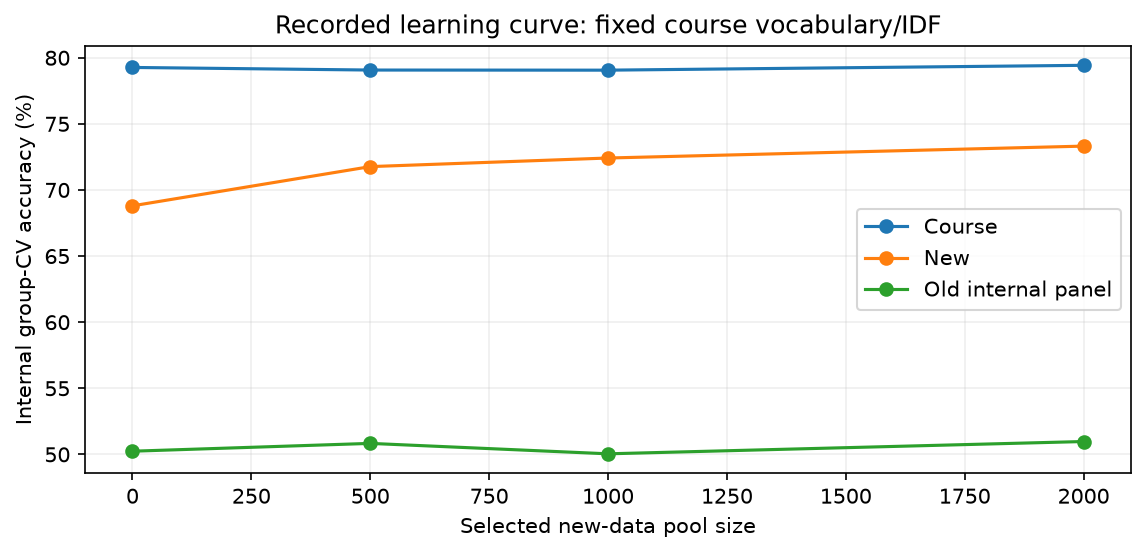

In [7]:
def new_pool_weights(course_count, new_labels):
    """Loss weights only: do not apply these values to TF-IDF document counts."""
    labels = np.asarray(new_labels)
    weights = np.ones(course_count+len(labels))
    for label in [0,1]:
        ii = np.flatnonzero(labels==label)
        if not len(ii):
            raise ValueError("Both publishers must occur in the selected new fitting pool")
        weights[course_count+ii] = 100*course_count/3730/len(ii)
    return weights

selection = load_result("new_selection")
learning = pd.DataFrame([{
    "case":r["name"],"new_pool_size":r["n"],"course_internal_pct":100*r["course"]["accuracy"],
    "new_internal_pct":100*r["new"]["accuracy"],"old_internal_pct":100*r["old_external_panel"]["accuracy"],
    "new_short_Fox_recall_pct":100*r["new_short_fox_recall"]}
    for r in selection["ranking"] if r["name"] in ["course_only","all_500","all_1000","all_2000"]])
learning = learning.sort_values("new_pool_size")
display(learning)
fig,ax = plt.subplots(figsize=(9,3.7))
for column,label in [("course_internal_pct","Course"),("new_internal_pct","New"),
                     ("old_internal_pct","Old internal panel")]:
    ax.plot(learning.new_pool_size,learning[column],"o-",label=label)
ax.set(xlabel="Selected new-data pool size",ylabel="Internal group-CV accuracy (%)",
       title="Recorded learning curve: fixed course vocabulary/IDF")
ax.legend(); ax.grid(alpha=.2)
show_figure(fig)

The all-2,000 configuration was locked before development inspection. Its new-pool internal
accuracy increased by about 4.52 percentage points, but the subsequent course dev decreased
from 772 to 765 correct. FoxNews correct increased 402→408; NBC correct decreased 370→357.
AUC improved on course dev even though thresholded accuracy decreased.
Historical external dev stayed at 129/306; paired dev decreased 112→108/200.
This distinction motivated the later representation/regularization/threshold study.
The development gate failed; the new pool was not automatically applied to v4.

In [ ]:
new_results = load_result("new_results")
new_dev = [saved_metric_row("New 2,000",case,panel,m)
           for case,record in new_results["models"].items() for panel,m in record["development"].items()]
display(pd.DataFrame(new_dev))
print({key:new_results[key] for key in ["cv_gate_passed","development_gate_passed","apply_to_v4"]})
display(load_result("new_cpu"))
reference(EXPERIMENTS+"new_data_v3_2026-10-29/prepare.py")
reference(EXPERIMENTS+"new_data_v3_2026-10-29/train.py")

## 7. Event pairing and V4 heads

Construct same-event publisher pairs, then compare frozen-encoder head and fusion settings.

[Saved evidence](experiments/historical/paired_results.json)


The collection and curation implementations are in [01 — Data collection and cleaning](01_Data_Collection_and_Cleaning.ipynb#12-archived-collection-and-event-pairing-source).


### train_heads.py.txt

<a id="source-quality-pipeline-experiments-paired-news-v4-2026-10-28-train-heads-py"></a>

quality_pipeline/experiments/paired_news_v4_2026-10-28/train_heads.py

**What this code does.** Tests V4 head and fusion settings using the paired data. It prepares reusable representations, fits classifier heads, compares score combinations, and estimates uncertainty by event group.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Frozen-feature v4 head adaptation with event-grouped training-only selection."""
    from support import *
    import copy,gc,resource
    import numpy as np,torch
    from scipy import sparse
    from sklearn.model_selection import KFold
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    torch.set_num_threads(1);resource.setrlimit(resource.RLIMIT_CPU,(900,903))
    sys.path.insert(0,str(PROJECT/'DragonThree_v4'))
    adv=load(PROJECT/'DragonThree_v4/advanced_search.py','paired_advanced')
    exp=load(PROJECT/'DragonThree_v4/export.py','paired_export')
    sys.path.insert(0,str(PIPE))
    from common import metric_values
    BASE=PIPE/'experiments/masking_styledistance_2026-10-28/v4_transfer/baseline_model'
    runtime=load(BASE/'model.py','paired_runtime')
    recipe=json.loads((PROJECT/'DragonThree_v4/results/ensemble_selection.json').read_text())['selected']
    course=[r for r in read(PIPE/'training/training_metadata.csv') if r['origin']=='course']
    paired=read(ROOT/'paired_train.csv')
    ctx=[r['text'] for r in course];etx=[r['text'] for r in paired]
    y=np.array([r['label']=='NBC' for r in course],int);ey=np.array([r['publisher']=='NBC' for r in paired],int)
    base_model=exp.load_bundle(BASE);base_model._decode();tokenizer=base_model._tokenizer
    
    def features(texts,vec=None,sc=None):
     if vec is None:
      vec={n:adv.make_vectorizer(n) for n in ('word12','char25')};X=sparse.hstack([v.fit_transform(texts) for v in vec.values()],format='csr');N=adv.numeric_features(texts);sc=StandardScaler().fit(N)
     else:X=sparse.hstack([v.transform(texts) for v in vec.values()],format='csr');N=adv.numeric_features(texts)
     return X,N,vec,sc
    def balancing(texts,labels):
     bins=np.array([0 if len(t.split())<=5 else 1 if len(t.split())<=8 else 2 if len(t.split())<=12 else 3 for t in texts]);weights=np.ones(len(texts))
     for label in (0,1):
      for b in range(4):
       ix=(labels==label)&(bins==b)
       if ix.sum():weights[ix]=np.clip(np.sqrt(np.mean(bins==b)/np.mean(bins[labels==label]==b)),.75,1.5)
      weights[labels==label]/=weights[labels==label].mean()
     return weights
    @torch.inference_mode()
    def embeddings(model,texts):
     out=[]
     for start in range(0,len(texts),64):
      ids,mask=tokenizer.batch(texts[start:start+64]);h=model.encoder(ids,mask);E=(h*mask.unsqueeze(-1)).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
      out.append(torch.nn.functional.normalize(E,p=2,dim=1).numpy())
     return np.concatenate(out).astype(np.float64)
    def model_features(models,texts,cache):
     digest=hashlib.sha256('\n'.join(texts).encode()).hexdigest()
     if cache.exists():
      z=np.load(cache);assert z['digest'].item()==digest;return z['X']
     E=np.stack([embeddings(m,texts) for m in models]);np.savez_compressed(cache,X=E,digest=digest);return E
    def fit_blocks(tr,er,models,E):
     tr=np.asarray(tr);er=np.asarray(er);train_texts=[ctx[i] for i in tr];external_texts=[etx[i] for i in er]
     X,N,vec,sc=features(train_texts);Z,M,_,_=features(external_texts,vec,sc)
     weights=balancing(train_texts,y[tr]);labels=np.r_[y[tr],ey[er]]
     basefits=[];adapt={.25:[],1.:[]}
     for item in recipe['members']:
      spec=item['spec'];A=adv.matrix(X,N,sc,spec);B=adv.matrix(Z,M,sc,spec)
      base=adv.classifier(spec).fit(A,y[tr]);basefits.append((vec,sc,base))
      for w in adapt:
       clf=adv.classifier(spec).fit(sparse.vstack([A,B],format='csr'),labels,sample_weight=np.r_[weights,np.full(len(er),w)])
       adapt[w].append((vec,sc,clf))
     heads={.25:[],1.:[]}
     for k,model in enumerate(models):
      oldw=model.head.weight.detach().numpy()[0].astype(float);oldb=float(model.head.bias.detach()[0]);oldscale=np.std(E[k,tr]@oldw+oldb)
      for w in heads:
       h=LogisticRegression(C=10.,solver='liblinear',random_state=42,max_iter=3000).fit(np.concatenate([E[k,tr],E[k,len(ctx)+er]]),labels,sample_weight=np.r_[weights,np.full(len(er),w)])
       scale=oldscale/max(np.std(E[k,tr]@h.coef_[0]+h.intercept_[0]),1e-8)
       heads[w].append((h.coef_[0]*scale,float(h.intercept_[0])*scale))
     return basefits,adapt,heads
    def sparse_parts(fits,texts):return np.mean([adv.advanced_scores(f,texts,s['spec'])/s['score_scale'] for f,s in zip(fits,recipe['members'])],axis=0)
    def score_grid(fits,adapt,heads,models,E,texts,indices):
     bs=sparse_parts(fits,texts);ss={w:sparse_parts(f,texts) for w,f in adapt.items()}
     old=np.mean([E[k,indices]@m.head.weight.detach().numpy()[0]+m.head.bias.item() for k,m in enumerate(models)],axis=0)
     new={w:np.mean([E[k,indices]@p[0]+p[1] for k,p in enumerate(h)],axis=0) for w,h in heads.items()}
     result=[]
     for c in cases:
      l=c['head_interpolation'];w=c['external_weight'];beta=c['semantic_weight']
      sp=bs if l==0 else (1-l)*bs+l*ss[w];ne=old if l==0 else (1-l)*old+l*new[w]
      result.append((1-beta)*sp+beta*ne/recipe['neural_scale']-recipe['threshold'])
     return np.stack(result)
    cases=[{'name':'baseline','external_weight':0.,'head_interpolation':0.,'semantic_weight':.25}]
    for w in (.25,1.):
     for l in (.25,.5,1.):
      for b in (.15,.25,.35):cases.append({'name':f'ext{w}_mix{l}_sem{b}','external_weight':w,'head_interpolation':l,'semantic_weight':b})
    for b in (.15,.35):cases.append({'name':f'fusion_only_{b}','external_weight':0.,'head_interpolation':0.,'semantic_weight':b})
    
    def group_ci(diff,groups):
     keys=sorted(set(groups));cnt=np.array([sum(x==g for x in groups) for g in keys]);tot=np.array([sum(d for d,x in zip(diff,groups) if x==g) for g in keys]);rng=np.random.default_rng(5190)
     ix=rng.integers(len(keys),size=(2000,len(keys)));v=tot[ix].sum(1)/cnt[ix].sum(1);return np.quantile(v,[.025,.975]).tolist()
    
    def main():
     out=ROOT/'head_results';out.mkdir(exist_ok=True)
     if (out/'selection.json').exists():raise RuntimeError('Selection already locked; do not reselect from development.')
     groups=sorted({r['event_group'] for r in paired});eg=np.array([r['event_group'] for r in paired]);course_groups=[r['cv_group'] for r in course]
     efolds=list(KFold(3,shuffle=True,random_state=5190).split(groups))
     cs=np.full((len(cases),len(ctx)),np.nan);es=np.full((len(cases),len(etx)),np.nan);logs=[]
     alltx=ctx+etx
     for fold in range(3):
      started=time.process_time();ind=np.load(ROOT/'fold_encoders'/f'indices_{fold}.npz');tr,va=ind['train'],ind['validation']
      et,ev=efolds[fold];etr=np.flatnonzero(np.isin(eg,[groups[i] for i in et]));eva=np.flatnonzero(np.isin(eg,[groups[i] for i in ev]))
      assert not set(eg[etr])&set(eg[eva])
      models=[]
      for seed in recipe['neural_seeds']:
       m=runtime.SemanticClassifier();m.load_state_dict(torch.load(ROOT/'fold_encoders'/f'fold{fold}_seed{seed}.pt',map_location='cpu',weights_only=True));m.eval();models.append(m)
      E=model_features(models,alltx,out/f'fold{fold}_features.npz');fits,adapt,heads=fit_blocks(tr,etr,models,E)
      cs[:,va]=score_grid(fits,adapt,heads,models,E,[ctx[i] for i in va],va)
      es[:,eva]=score_grid(fits,adapt,heads,models,E,[etx[i] for i in eva],len(ctx)+eva)
      logs.append({'fold':fold,'course_training':len(tr),'course_validation':len(va),'paired_training':len(etr),'paired_validation':len(eva),'cpu_seconds':time.process_time()-started})
      print('HEAD_FOLD',json.dumps(logs[-1]),flush=True);del models,E,fits,adapt,heads;gc.collect()
     assert np.isfinite(cs).all() and np.isfinite(es).all()
     cacc=np.mean((cs>0)==y,axis=1);eacc=np.mean((es>0)==ey,axis=1)
     ranking=[]
     for i,c in enumerate(cases):
      cd=((cs[i]>0)==y).astype(float)-((cs[0]>0)==y);ed=((es[i]>0)==ey).astype(float)-((es[0]>0)==ey)
      ranking.append({**c,'index':i,'course_accuracy':float(cacc[i]),'paired_accuracy':float(eacc[i]),'course_delta':float(cd.mean()),'paired_delta':float(ed.mean()),'course_delta_group_ci95':group_ci(cd,course_groups),'paired_delta_event_ci95':group_ci(ed,eg),'eligible':bool(cacc[i]>=cacc[0]-.005)})
     eligible=[r for r in ranking if r['eligible']]
     chosen=sorted(eligible,key=lambda r:(-r['paired_accuracy'],-r['course_accuracy'],r['head_interpolation'],abs(r['semantic_weight']-.25)))[0]
     selection={'selected':chosen,'ranking':ranking,'baseline':ranking[0],'folds':logs,'development_used_for_selection':False,'no_threshold_search':True,'uncertainty':'OOF confidence intervals after candidate selection are exploratory; fresh confirmation is separate.'}
     dump(out/'selection.json',selection);np.savez_compressed(out/'training_oof.npz',course_scores=cs,paired_scores=es,y=y,paired_y=ey,course_groups=course_groups,paired_groups=eg)
     print('LOCKED_SELECTION',json.dumps(chosen),flush=True)
     # Full-data encoder weights are inherited unchanged from the matched cleaned-course v4.
     models=list(base_model.semantic);E=model_features(models,alltx,out/'full_features.npz')
     fits,adapt,heads=fit_blocks(np.arange(len(ctx)),np.arange(len(etx)),models,E)
     l=chosen['head_interpolation'];w=chosen['external_weight'];selectedfits=[]
     for k,fit in enumerate(fits):
      vec,sc,clf=fit;clf=copy.deepcopy(clf)
      if l:
       clf.coef_=(1-l)*clf.coef_+l*adapt[w][k][2].coef_;clf.intercept_=(1-l)*clf.intercept_+l*adapt[w][k][2].intercept_
      selectedfits.append((vec,sc,clf))
     states=[]
     for k,m in enumerate(models):
      state={n:v.detach().clone() for n,v in m.state_dict().items()}
      if l:
       nw,nb=heads[w][k];state['head.weight']=(1-l)*state['head.weight']+l*torch.tensor(nw[None,:],dtype=state['head.weight'].dtype)
       state['head.bias']=(1-l)*state['head.bias']+l*torch.tensor([nb],dtype=state['head.bias'].dtype)
      assert all(torch.equal(state[n],v) for n,v in m.state_dict().items() if n.startswith('encoder.'))
      states.append(state)
     selectedrecipe={**recipe,'semantic_weight':chosen['semantic_weight']}
     candidate=exp.export_bundle(selectedfits,states,selectedrecipe,out/'candidate_model')
     # Only now evaluate original development and fresh event-disjoint confirmation.
     datasets={'course_dev':read(PROJECT/'baseline/data/val.csv'),'external_dev':read(PIPE/'data/external_dev_urls.csv'),'paired_confirmation':read(ROOT/'paired_confirmation.csv')}
     results={};pred=[]
     trainurls={r['url'] for r in course+paired};traintexts={norm(r['text']) for r in course+paired}
     for ds,rows in datasets.items():
      tx=[pp.url_to_text(r['url']) for r in rows];yy=np.array([pp.label_from_url(r['url'])=='NBC' for r in rows],int)
      assert not trainurls&{r['url'] for r in rows} and not traintexts&set(map(norm,tx))
      old=base_model.decision_function(tx);s=candidate.decision_function(tx)
      # Export parity against independent matrix and neural implementations.
      ref=exp.reference_sparse(selectedfits,tx,selectedrecipe)
      with torch.inference_mode():
       nn=[];baseline_nn=[]
       for k,state in enumerate(states):
        m=runtime.SemanticClassifier();m.load_state_dict(state);m.eval();z=embeddings(m,tx);nn.append(z@m.head.weight.detach().numpy()[0]+m.head.bias.item())
        baseline_nn.append(z@models[k].head.weight.detach().numpy()[0]+models[k].head.bias.item())
       ref+=np.mean(nn,axis=0)*selectedrecipe['semantic_weight']/recipe['neural_scale']
      np.testing.assert_allclose(s,ref,atol=2e-6,rtol=2e-6)
      oldref=exp.reference_sparse(fits,tx,recipe)+np.mean(baseline_nn,axis=0)*recipe['semantic_weight']/recipe['neural_scale']
      np.testing.assert_allclose(old,oldref,atol=2e-6,rtol=2e-6)
      delta=((s>0)==yy).astype(float)-((old>0)==yy)
      g=[r.get('event_group') or norm(t) for r,t in zip(rows,tx)]
      results[ds]={'baseline':metric_values(yy,old>0,old),'candidate':metric_values(yy,s>0,s),'fixed_errors':int(np.sum(((old>0)!=yy)&((s>0)==yy))),'new_errors':int(np.sum(((old>0)==yy)&((s>0)!=yy))),'accuracy_delta_ci95':group_ci(delta,g),'ci_grouping':'event' if ds=='paired_confirmation' else 'normalized_text_only_not_verified_events'}
      for r,t,truth,bs,ss in zip(rows,tx,yy,old,s):pred.append({'dataset':ds,'url':r['url'],'text':t,'actual':'NBC' if truth else 'FoxNews','baseline_score':float(bs),'candidate_score':float(ss),'baseline_correct':bool((bs>0)==truth),'candidate_correct':bool((ss>0)==truth),'event_group':r.get('event_group','')})
     plan=json.loads((ROOT/'preregistered_plan.json').read_text());assert all(sha(Path(p))==v for p,v in plan['protected_models'].items())
     gate=results['course_dev']['candidate']['accuracy']>=results['course_dev']['baseline']['accuracy']-.005 and results['external_dev']['candidate']['accuracy']>=results['external_dev']['baseline']['accuracy'] and results['paired_confirmation']['candidate']['accuracy']>results['paired_confirmation']['baseline']['accuracy']
     result={'selected':chosen,'development':results,'confirmation_gate_passed':bool(gate),'existing_submission_replaced':False,'encoder_weights_unchanged':True,'export_parity':True,'final_test_accessed':False,'csv_paths_opened':sorted(READS),'cpu_seconds':time.process_time()}
     dump(out/'results.json',result);save(out/'development_predictions.csv',pred);print('HEAD_RESULTS',json.dumps(result),flush=True)
    if __name__=='__main__':main()


### Event-paired news: frozen encoders, new heads and fusion

**Data:** 800 paired training records; 200 separate event-grouped confirmation records.
**Procedure:** keep v4 encoders frozen; vary external loss weight, head interpolation, and semantic
fusion weight. The selected configuration used external weight .25, head interpolation 1,
and semantic weight .25. This is a head/fusion experiment, not complete encoder retraining.
The matched control and candidate both scored 809/951 on course dev; paired dev rose from
115/200 to 129/200, while historical external dev changed from 143/306 to 142/306.
These mixed outcomes did not justify replacing the original submission.

In [5]:
paired = load_result("paired_results")
display(paired["selected"])
paired_dev = [saved_metric_row("Paired v4 heads",case,panel,m)
              for panel,entries in paired["development"].items()
              for case,m in entries.items() if case in ["baseline","candidate"]]
display(pd.DataFrame(paired_dev))
print("Confirmation gate passed:",paired["confirmation_gate_passed"])
reference(EXPERIMENTS+"paired_news_v4_2026-10-28/train_heads.py")

{'name': 'ext0.25_mix1.0_sem0.25',
 'external_weight': 0.25,
 'head_interpolation': 1.0,
 'semantic_weight': 0.25,
 'index': 8,
 'course_accuracy': 0.8335120643431635,
 'paired_accuracy': 0.6975,
 'course_delta': -0.0018766756032171583,
 'paired_delta': 0.035,
 'course_delta_group_ci95': [-0.009651603976573197, 0.005907626208378088],
 'paired_delta_event_ci95': [0.01125, 0.05875],
 'eligible': True}

,study,case,panel,n,correct,accuracy_pct,balanced_accuracy_pct,macro_f1,ROC_AUC
0,Paired v4 heads,baseline,course_dev,951,809,85.068349,85.070544,0.850624,0.922335
1,Paired v4 heads,candidate,course_dev,951,809,85.068349,85.071207,0.850580,0.926338
2,Paired v4 heads,baseline,external_dev,306,143,46.732026,46.732026,0.422782,0.410141
3,Paired v4 heads,candidate,external_dev,306,142,46.405229,46.405229,0.424733,0.439105
4,Paired v4 heads,baseline,paired_confirmation,200,115,57.500000,57.500000,0.574734,0.636400
5,Paired v4 heads,candidate,paired_confirmation,200,129,64.500000,64.500000,0.644778,0.704700


Confirmation gate passed: False


Historical implementation: [quality_pipeline/experiments/paired_news_v4_2026-10-28/train_heads.py](source_archive/quality_pipeline/experiments/paired_news_v4_2026-10-28/train_heads.py.txt)

## 8. Vocabulary, IDF and regularization

Separate representation changes from C and threshold choices; preserve the historical partial nested run as recorded.

[Saved evidence](experiments/historical/latest_summary.json)


### study.py.txt

<a id="source-quality-pipeline-experiments-v3-feature-regularization-2026-10-29-study-py"></a>

quality_pipeline/experiments/v3_feature_regularization_2026-10-29/study.py

**What this code does.** Separates vocabulary and IDF changes from regularization and decision-threshold effects. It fits controlled comparisons, selects policies inside the inner folds, and records completed work when the CPU budget stops the run.

The following historical code cell is disabled during review.


In [ ]:
if False:  # Archived source. Keep disabled during notebook review.
    """Nested grouped comparison of feature representation, regularization and threshold."""
    from support import *
    import time,resource,warnings,gc,math
    import numpy as np
    from scipy import sparse
    from sklearn.base import clone
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.svm import LinearSVC
    from sklearn.exceptions import ConvergenceWarning
    from sklearn.preprocessing import normalize
    import torch
    torch.set_num_threads(1)
    remaining=float(os.environ.get('EXPERIMENT_CPU_REMAINING','295'))
    soft_limit=max(1,int(remaining-2));resource.setrlimit(resource.RLIMIT_CPU,(soft_limit,soft_limit+1))
    stop_cpu=remaining-float(os.environ.get('EXPERIMENT_CPU_RESERVE','24'))
    class BudgetStop(Exception):pass
    def budget():
        if time.process_time()>stop_cpu:raise BudgetStop('Reserve export/report time within 300 CPU seconds')
    sys.path.insert(0,str(PROJECT/'DragonThree_v3'))
    search=load(PROJECT/'DragonThree_v3/search.py','feature_search')
    exporter=load(PROJECT/'DragonThree_v3/train_export.py','feature_export')
    pp=load(PROJECT/'DragonThree_v3/preprocess.py','feature_pp')
    sys.path.insert(0,str(PIPE))
    from common import metric_values
    plan=json.loads((ROOT/'preregistered_plan.json').read_text())
    rs=jl(PREV/'audited_training_rows.jsonl');folds=json.loads((PREV/'folds.json').read_text())
    texts=[r['text'] for r in rs];y=np.array([r['label']=='NBC' for r in rs],int)
    group=np.array([r['group'] for r in rs]);origin=np.array([r['origin'] for r in rs]);words=np.array([r['words'] for r in rs])
    course=origin=='course';new=origin=='new';old=np.isin(origin,['legacy','paired'])
    strata=np.array([{'course':0,'legacy':1,'paired':2,'new':3}[r['origin']]*2+int(r['label']=='NBC') for r in rs])
    REPS=['A','B','C','D'];CS=plan['C_values'];TS=plan['thresholds'];SCALE=plan['score_scale'];TI=TS.index(-.05);CI=CS.index(4.)
    POLICIES=[f'{r}_{mode}' for mode in ('fixed','C','threshold','joint') for r in REPS]+['augmented_joint']
    fit_logs=[];feature_logs=[];split_logs=[];selection_logs=[];training_logs=[]
    
    def representations(tr,tag):
        """All learned transforms use only course/new members of tr, never panel/validation."""
        budget();ct=tr[course[tr]];nt=tr[new[tr]];joint=np.r_[ct,nt]
        a={n:search.make_vectorizer(n).fit([texts[i] for i in ct]) for n in ('word12','char25')}
        c={n:clone(v).set_params(vocabulary=dict(v.vocabulary_)).fit([texts[i] for i in joint]) for n,v in a.items()}
        d={n:search.make_vectorizer(n).fit([texts[i] for i in joint]) for n in a}
        for n in a:
            assert a[n].vocabulary_==c[n].vocabulary_
            # On this corpus char count is below its original 120k cap; a true expansion.
            assert set(a[n].vocabulary_)<=set(d[n].vocabulary_), 'Feature cap pruned course terms; stop rather than change protocol'
            common=np.array([d[n].vocabulary_[term] for term in a[n].get_feature_names_out()])
            np.testing.assert_allclose(c[n].idf_,d[n].idf_[common],rtol=0,atol=1e-12)
        vectors={'A':a,'B':a,'C':c,'D':d};matrices={}
        ablocks={n:v.transform(texts) for n,v in a.items()}
        dblocks={n:v.transform(texts) for n,v in d.items()}
        # Algebraically identical C transform: restrict joint-IDF D to the fixed
        # course vocabulary, then re-normalize each block. Avoid re-tokenization.
        cblocks={n:normalize(dblocks[n][:,[d[n].vocabulary_[t] for t in a[n].get_feature_names_out()]],norm='l2',copy=True) for n in a}
        for r,blocks in [('A',ablocks),('C',cblocks),('D',dblocks)]:
            matrices[r]=sparse.hstack(list(blocks.values()),format='csr')
        for n in a:
            ix=tr[:min(32,len(tr))]
            np.testing.assert_allclose(cblocks[n][ix].toarray(),c[n].transform([texts[i] for i in ix]).toarray(),atol=1e-12,rtol=1e-12)
        matrices['B']=matrices['A']
        feature_logs.append(dict(tag=tag,course_fit_rows=len(ct),new_fit_rows=len(nt),
         feature_counts={r:{n:len(v.vocabulary_) for n,v in vectors[r].items()} for r in ('A','C','D')},
         C_vocabulary_equals_A=True,D_retains_A=True,C_D_common_idf_equal=True))
        return vectors,matrices
    
    def fit(X,tr,rep,C,tag):
        budget();ct=tr[course[tr]];nt=tr[new[tr]] if rep!='A' else np.array([],int)
        ix=np.r_[ct,nt];weights=np.ones(len(ix))
        if len(nt):
            for label in (0,1):
                where=np.flatnonzero(y[nt]==label);assert len(where)>0
                weights[len(ct)+where]=100*len(ct)/3730/len(where)
        model=LinearSVC(C=C,dual=True,max_iter=20000,random_state=42)
        with warnings.catch_warnings(record=True) as ws:
            warnings.simplefilter('always',ConvergenceWarning);model.fit(X[ix],y[ix],sample_weight=weights)
        assert not any(issubclass(w.category,ConvergenceWarning) for w in ws),'SVM did not converge'
        fit_logs.append(dict(tag=tag,representation=rep,C=C,course_rows=len(ct),new_rows=len(nt),
         new_loss_mass=float(weights[len(ct):].sum()),iterations=int(model.n_iter_)))
        return model
    
    def grid_fit(tr,va,tag,training_diagnostics=False):
        assert not set(group[tr])&set(group[va])
        vectors,X=representations(tr,tag);result=np.empty((4,4,len(va)))
        for ri,r in enumerate(REPS):
            for ci,C in enumerate(CS):
                m=fit(X[r],tr,r,C,tag);result[ri,ci]=m.decision_function(X[r][va])/SCALE
                if training_diagnostics:
                    tm={}
                    for label,mask in [('course_train',course),('new_fit_rows' if r!='A' else 'new_not_fitted',new)]:
                        ii=tr[mask[tr]];s=m.decision_function(X[r][ii])/SCALE
                        tm[label]=dict(n=len(ii),accuracy=float(((s>-.05)==y[ii]).mean()))
                    training_logs.append(dict(tag=tag,representation=r,C=C,threshold=-.05,**tm))
        del X,vectors;gc.collect();return result
    
    def candidate_records(raw,scope):
        """raw shape repeat x representation x C x all-records; only scope is inspected."""
        records=[]
        masks={'course':scope[course[scope]],'new':scope[new[scope]],'old':scope[old[scope]],
               'course_nbc':scope[course[scope]&(y[scope]==1)]}
        for ri,r in enumerate(REPS):
            for ci,C in enumerate(CS):
                assert np.isfinite(raw[:,ri,ci,scope]).all()
                values={}
                for k,ix in masks.items():
                    p=raw[:,ri,ci,ix,None]>np.array(TS)
                    values[k]=np.mean(p==y[ix][None,:,None],axis=(0,1))
                for ti,t in enumerate(TS):records.append(dict(rep=r,C=C,threshold=t,**{k:float(v[ti]) for k,v in values.items()}))
        return records
    
    def fixed(records,rep='A'):
        return next(r for r in records if r['rep']==rep and r['C']==4 and r['threshold']==-.05)
    def choose(records,reps,mode,reference):
        pool=[r for r in records if r['rep'] in reps and (mode not in ('fixed','threshold') or r['C']==4) and (mode not in ('fixed','C') or r['threshold']==-.05)]
        eligible=[r for r in pool if r['course']>=reference['course']-.005-1e-12 and
         r['course_nbc']>=reference['course_nbc']-.01-1e-12 and r['old']>=reference['old']-1e-12]
        if not eligible:return dict(fixed(records,reps[0]),eligible=False,fallback=True)
        row=sorted(eligible,key=lambda r:(-(r['new']+r['old'])/2,-r['course'],r['C'],abs(r['threshold']+.05),r['rep']))[0]
        return dict(row,eligible=True,fallback=False)
    def select_policies(records):
        baseline=fixed(records);selected={}
        for mode in ('fixed','C','threshold','joint'):
            for r in REPS:
                selected[f'{r}_{mode}']=dict(fixed(records,r),eligible=True,fallback=False) if mode=='fixed' else choose(records,[r],mode,baseline)
        tuned=selected['A_joint'];reference={k:max(baseline[k],tuned[k]) for k in ('course','course_nbc','old')}
        selected['augmented_joint']=choose(records,['B','C','D'],'joint',reference)
        return selected
    
    def inner(tr,seed,tag):
        raw=np.full((1,4,4,len(rs)),np.nan)
        splitter=StratifiedGroupKFold(3,shuffle=True,random_state=seed)
        for fi,(a,b) in enumerate(splitter.split(np.zeros(len(tr)),strata[tr],group[tr])):
            it,iv=tr[a],tr[b];assert not set(group[it])&set(group[iv])
            split_logs.append(dict(tag=tag,fold=fi,train=it.tolist(),validation=iv.tolist()))
            raw[0,:,:,iv]=np.moveaxis(grid_fit(it,iv,tag+f'_inner{fi}'),-1,0)
        return select_policies(candidate_records(raw,tr))
    
    def metric(scores,mask):
        vals=[metric_values(y[mask],s[mask]>0,s[mask]) for s in scores]
        return dict(n=int(mask.sum()),accuracy=float(np.mean([v['accuracy'] for v in vals])),
         accuracy_by_seed=[v['accuracy'] for v in vals],balanced_accuracy=float(np.mean([v['balanced_accuracy'] for v in vals])),
         macro_f1=float(np.mean([v['macro_f1'] for v in vals])),roc_auc=float(np.mean([v['roc_auc'] for v in vals])),
         fox_recall=float(np.mean([v['per_class']['FoxNews']['recall'] for v in vals])),
         nbc_recall=float(np.mean([v['per_class']['NBC']['recall'] for v in vals])))
    def bootstrap(diff,mask):
        # Paired group-bootstrap conditional on saved folds; not independent-test evidence.
        g,inv=np.unique(group[mask],return_inverse=True);counts=np.bincount(inv);sums=np.bincount(inv,weights=diff[mask])
        rng=np.random.default_rng(5190);draws=[]
        for _ in range(20):
            ix=rng.integers(len(g),size=(250,len(g)));draws.extend((sums[ix].sum(1)/counts[ix].sum(1)).tolist())
        return np.quantile(draws,[.025,.975]).tolist()
    
    def summarize(raw,policy_scores):
        summary=[]
        for pi,p in enumerate(POLICIES):
            s=policy_scores[:,pi];summary.append(dict(policy=p,course=metric(s,course),new=metric(s,new),old=metric(s,old),
             new_short_fox_recall=float(((s[:,new&(y==0)&(words<=5)]>0)==0).mean()),
             new_short_nbc_recall=float(((s[:,new&(y==1)&(words<=5)]>0)==1).mean())))
        by={r['policy']:r for r in summary};primary=POLICIES.index('augmented_joint');base=POLICIES.index('A_joint');fixed_i=POLICIES.index('A_fixed')
        correct=(policy_scores>0)==y;diff=correct[:,primary].mean(0)-correct[:,base].mean(0)
        deltas={k:dict(delta=float(diff[m].mean()),ci95=bootstrap(diff,m)) for k,m in [('course',course),('new',new),('old',old)]}
        nd=correct[:,primary,new].mean(1)-correct[:,base,new].mean(1)
        c=by['augmented_joint'];a=by['A_joint'];f=by['A_fixed']
        gate=bool(c['course']['accuracy']>=max(a['course']['accuracy'],f['course']['accuracy'])-.005 and
         c['course']['nbc_recall']>=max(a['course']['nbc_recall'],f['course']['nbc_recall'])-.01 and
         c['old']['accuracy']>=max(a['old']['accuracy'],f['old']['accuracy']) and
         (nd>0).sum()>=2 and deltas['new']['ci95'][0]>0)
        curves=[]
        for ri,r in enumerate(REPS):
            for ci,C in enumerate(CS):
                s=raw[:,ri,ci]+.05
                logs=[l for l in training_logs if l['representation']==r and l['C']==C]
                curves.append(dict(representation=r,C=C,threshold=-.05,course=metric(s,course),new=metric(s,new),old=metric(s,old),
                 course_train_accuracy=float(np.mean([l['course_train']['accuracy'] for l in logs])),
                 new_train_accuracy=float(np.mean([l['new_fit_rows']['accuracy'] for l in logs])) if r!='A' else None))
        result=dict(policies=summary,regularization_curves=curves,primary_paired_deltas_vs_tuned_A=deltas,
         primary_new_gain_by_seed=nd.tolist(),internal_gate_passed=gate,
         primary_augmented_inner_eligible_folds=sum(r['choices']['augmented_joint']['eligible'] for r in selection_logs),
         final_test_accessed=False,uncertainty='Dependency bootstrap, conditional on reused training partitions; exploratory comparisons among secondary policies are not multiple-comparison adjusted.')
        dump(ROOT/'nested_results.json',result);return result
    
    def coverage(vectors):
        report={}
        for name,v in vectors.items():
            analyze=v.build_analyzer();known=v.vocabulary_;total=found=0;distinct=set();seen=set()
            for i in np.flatnonzero(new):
                terms=analyze(texts[i]);total+=len(terms);found+=sum(t in known for t in terms);distinct.update(terms);seen.update(t for t in terms if t in known)
            report[name]=dict(vocabulary=len(known),new_feature_occurrence_coverage=found/total,new_unique_feature_coverage=len(seen)/len(distinct),new_unique_features=len(distinct))
        return report
    
    def finish(raw,policies,summary):
        budget()
        # These cached fixed-grid folds exactly implement full-training CV search.
        # Nested estimates above were selected strictly in inner folds, without these outer outcomes.
        choices=select_policies(candidate_records(raw,np.arange(len(rs))))
        final=dict(tuned_course=choices['A_joint'],augmented=choices['augmented_joint'],
         cv_cache_reuse='Reuse fixed-grid outer fits for final all-training CV search; do NOT use best outer policy to change the procedure.',
         internal_gate_passed=summary['internal_gate_passed'],development_used_for_selection=False,final_test_accessed=False)
        dump(ROOT/'final_selection.json',final);print('LOCKED_FINAL_SELECTION',json.dumps(final),flush=True)
        development={'course_dev':read(PROJECT/'baseline/data/val.csv'),'external_dev':read(PIPE/'data/external_dev_urls.csv'),'paired_dev':read(PAIRED/'paired_confirmation.csv')}
        knownurls={r['url'] for r in rs};knowntexts=set(map(norm,texts));devdata={}
        for name,rr in development.items():
            tx=[pp.url_to_text(r['url']) for r in rr];assert not knownurls&{r['url'] for r in rr};assert not knowntexts&set(map(norm,tx))
            devdata[name]=(tx,np.array([pp.label_from_url(r['url'])=='NBC' for r in rr],int))
        vec,X=representations(np.arange(len(rs)),'final_full');results={};predictions=[]
        feature_coverage={r:coverage(vec[r]) for r in ('A','C','D')};dump(ROOT/'feature_coverage.json',feature_coverage)
        for name,spec in [('tuned_course',final['tuned_course']),('augmented',final['augmented'])]:
            r=spec['rep'];m=fit(X[r],np.arange(len(rs)),r,spec['C'],'final_'+name);offset=0;weights={}
            for n,v in vec[r].items():
                count=len(v.vocabulary_);weights[n]=m.coef_[0][offset:offset+count]/SCALE;offset+=count
            bias=float(m.intercept_[0])/SCALE-spec['threshold']
            model,_=exporter.export(vec[r],weights,bias,ROOT/'models'/name)
            checks={};training={}
            for label,mask in [('course',course),('new',new)]:
                ss=m.decision_function(X[r][mask])/SCALE-spec['threshold'];training[label]=metric_values(y[mask],ss>0,ss)
            for ds,(tx,yy) in devdata.items():
                V=sparse.hstack([v.transform(tx) for v in vec[r].values()],format='csr')
                reference=m.decision_function(V)/SCALE-spec['threshold'];actual=model.decision_function(tx)
                np.testing.assert_allclose(reference,actual,atol=1e-9,rtol=1e-9)
                checks[ds]=metric_values(yy,actual>0,actual)
                for row,text,truth,score in zip(development[ds],tx,yy,actual):predictions.append(dict(model=name,dataset=ds,url=row['url'],text=text,label=int(truth),score=float(score),words=len(text.split())))
            results[name]=dict(specification=spec,development=checks,in_sample_diagnostics=training,new_was_fitted=r!='A',export_parity=True)
            print('DEVELOPMENT',name,json.dumps(checks),flush=True)
        a=results['tuned_course']['development'];b=results['augmented']['development']
        devgate=bool(b['course_dev']['accuracy']>=a['course_dev']['accuracy']-.005 and
         b['course_dev']['per_class']['NBC']['recall']>=a['course_dev']['per_class']['NBC']['recall']-.01 and
         all(b[k]['correct']>=a[k]['correct'] for k in ('external_dev','paired_dev')) and any(b[k]['correct']>a[k]['correct'] for k in ('external_dev','paired_dev')))
        save(ROOT/'development_predictions.csv',predictions)
        outcome=dict(models=results,internal_gate_passed=summary['internal_gate_passed'],development_gate_passed=devgate,
         recommend_for_future_v4=bool(summary['internal_gate_passed'] and devgate and final['augmented']['eligible']),
         v4_trained=False,existing_models_replaced=False,final_test_accessed=False,dataset_reads=sorted(READS))
        dump(ROOT/'results.json',outcome);return outcome
    
    def main():
        if (ROOT/'final_selection.json').exists():raise RuntimeError('Final selection locked; refusing rerun')
        for p,h in plan['inputs'].items():assert sha(p)==h
        raw=np.full((3,4,4,len(rs)),np.nan);policies=np.full((3,len(POLICIES),len(rs)),np.nan);completed=[]
        try:
            for si,partition in enumerate(folds):
                for fi,part in enumerate(partition['parts']):
                    budget();start=time.process_time();tr=np.array(part['train']);va=np.array(part['validation']);tag=f'seed{partition["seed"]}_outer{fi}'
                    choices=inner(tr,partition['seed']*10+fi,tag)
                    block=grid_fit(tr,va,tag,training_diagnostics=True)
                    raw[si,:,:,va]=np.moveaxis(block,-1,0)
                    for pi,p in enumerate(POLICIES):
                        spec=choices[p];policies[si,pi,va]=block[REPS.index(spec['rep']),CS.index(spec['C'])]-spec['threshold']
                    selection_logs.append(dict(seed=partition['seed'],fold=fi,choices=choices));completed.append(tag)
                    dump(ROOT/'outer_choices.json',selection_logs)
                    np.savez_compressed(ROOT/'nested_oof.npz',raw_scores=raw,policy_scores=policies,y=y,origin=origin,groups=group,policies=POLICIES)
                    print('OUTER_DONE',json.dumps(dict(tag=tag,fold_cpu=round(time.process_time()-start,2),process_cpu=round(time.process_time(),2),tuned_A=choices['A_joint'],augmented=choices['augmented_joint'])),flush=True)
            assert np.isfinite(raw).all() and np.isfinite(policies).all()
            prior=np.load(PREV/'training_oof.npz');pc=prior['cases'].tolist()
            for r,name in [('A','course_only'),('B','all_2000')]:
                np.testing.assert_allclose(raw[:,REPS.index(r),CI]+.05,prior['scores'][:,pc.index(name)],rtol=0,atol=1e-8)
            summary=summarize(raw,policies);dump(ROOT/'baseline_reproduction.json',dict(A_exact=True,B_exact=True,tolerance=1e-8))
            result=finish(raw,policies,summary)
            assert all(sha(p)==h for p,h in plan['original_models'].items())
            dump(ROOT/'verification.json',dict(outer_group_disjoint=True,inner_group_disjoint=True,outer_validation_not_used_for_inner_selection=True,
             feature_fit_excludes_all_validation_and_old_panel=True,C_vocabulary_equals_A=True,D_retains_A=True,C_D_common_idf_equal=True,
             exact_prior_A_B_reproduction=True,all_SVM_converged=True,export_parity=True,original_models_hashes_unchanged=True,
             final_test_accessed=False,v4_trained=False,completed_outer_folds=len(completed),model_fits=len(fit_logs)))
            print('FINISHED',json.dumps(dict(recommend_for_future_v4=result['recommend_for_future_v4'],process_cpu=time.process_time(),fits=len(fit_logs))),flush=True)
        except BudgetStop as e:
            dump(ROOT/'incomplete.json',dict(reason=str(e),completed_outer_folds=completed,cpu_seconds=time.process_time(),final_test_accessed=False))
            print('BUDGET_STOP',str(e),flush=True)
        finally:
            save(ROOT/'fit_log.csv',fit_logs);dump(ROOT/'feature_log.json',feature_logs);dump(ROOT/'inner_splits.json',split_logs);dump(ROOT/'training_scores.json',training_logs)
    
    if __name__=='__main__':main()


### Latest study: separate vocabulary, IDF, regularization and threshold effects

The latest design kept the new-pool weighting rule unchanged and controlled each representation:

| Representation | Classifier fitting rows | Vocabulary | IDF fitting rows |
|---|---|---|---|
| A | Course | Course | Course |
| B | Course + new | Same as A | Same as A |
| C | Course + new | Same as A | Course + new |
| D | Course + new | Expanded; retains every A term | Course + new |

All entries mean the current fitting fold only. IDF is standard **unweighted** document frequency.
The old internal panel cannot fit coefficients, vocabulary or IDF. Shared C/D terms have equal IDF;
each word/character block is L2-normalized separately. New vocabulary cannot silently prune A terms.
The helper below expresses the same transformations directly, without the historical cache
optimization. It is a definition only; no fitting occurs in this notebook's review run.

In [9]:
from dragonthree.models_v1_v5 import LexicalV2V3

def fit_representations(course_texts, new_texts):
    """For an explicitly authorized future fit; caller must provide only fitting-fold rows."""
    joint_texts = list(course_texts)+list(new_texts)
    A = [v.fit(course_texts) for v in LexicalV2V3("v3").make_vectors()]
    C = [clone(v).set_params(vocabulary=dict(v.vocabulary_)).fit(joint_texts) for v in A]
    D = [v.fit(joint_texts) for v in LexicalV2V3("v3").make_vectors()]
    for a,c,d in zip(A,C,D):
        assert a.vocabulary_ == c.vocabulary_
        if not set(a.vocabulary_) <= set(d.vocabulary_):
            raise ValueError("Expanded feature cap pruned a course feature; protocol cannot continue")
        common = [d.vocabulary_[t] for t in a.get_feature_names_out()]
        np.testing.assert_allclose(c.idf_,d.idf_[common],atol=1e-12,rtol=0)
    return {"A":A,"B":A,"C":C,"D":D}

def transform_representation(vectors, texts):
    return sparse.hstack([v.transform(texts) for v in vectors],format="csr")

latest_plan = load_result("latest_plan")
display({k:latest_plan[k] for k in ["representations","weights","C_values","thresholds",
    "score_scale","outer","inner","objective","selection_reference","gate"]})

{'representations': {'A': 'Course-fitted classifier; course vocabulary and IDF.',
  'B': 'Course+new classifier; course vocabulary and IDF.',
  'C': 'Course+new classifier; identical course vocabulary; standard unweighted IDF fitted on course+new training-fold records.',
  'D': 'Course+new classifier; expanded vocabulary and standard unweighted IDF fitted on course+new training-fold records; retain all course vocabulary terms. Original word12/char25 settings and caps.'},
 'weights': 'Exactly prior recipe: course weight=1; new total mass=200*(course training-fold n/3730), split equally between outlets; within-outlet per-row normalization. Full refit gives every new row weight .1. IDF counts each fitting document once, without classifier sample weights.',
 'C_values': [0.25, 1.0, 4.0, 16.0],
 'thresholds': [-0.5,
  -0.45,
  -0.4,
  -0.35,
  -0.3,
  -0.25,
  -0.2,
  -0.15,
  -0.1,
  -0.05,
  0.0,
  0.05,
  0.1,
  0.15,
  0.2,
  0.25,
  0.3,
  0.35,
  0.4,
  0.45,
  0.5],
 'score_scale': 0

**Selection protocol:** C ∈ {.25, 1, 4, 16}; threshold from −.50 to +.50 by .05.
The old v3 score scale remains fixed at 0.776760627876633.
Each A–D representation has fixed, C-only, threshold-only, and joint policies; the primary
augmented policy chooses B/C/D jointly within inner CV. Each outer training split has three
group-disjoint inner folds; feature fitting is repeated inside each inner fitting split.
The objective is mean(new accuracy, old internal-panel accuracy), subject to course accuracy
loss ≤.005, NBC recall loss ≤.01, and no old-panel loss. The augmented policy protects both
fixed A and equally tuned A by taking the metricwise maximum as its reference.
Course-only A receives the same internal selection information, but fits course rows only.
Outer results cannot be used to switch to the most favorable policy.

### Latest completed evidence: fixed controls versus partial nested validation

**Fixed comparisons: all 9/9 outer folds completed.** These rows use C=4 and threshold −.05.
Their CV values are internal scores, not 951-row dev results.

In [11]:
latest = load_result("latest_summary")
fixed = pd.DataFrame([{"representation":r["representation"],"C":r["C"],"threshold":r["threshold"],
    **{panel+"_internal_pct":100*r[panel]["accuracy"] for panel in ["course","new","old"]},
    "course_fit_accuracy_pct":100*r["course_train_accuracy"],
    "new_fit_accuracy_pct":None if r["new_train_accuracy"] is None else 100*r["new_train_accuracy"]}
    for r in latest["fixed_feature_results"]])
display(fixed)

,representation,C,threshold,course_internal_pct,new_internal_pct,old_internal_pct,course_fit_accuracy_pct,new_fit_accuracy_pct
0,A,4.0,-0.05,79.267203,68.800000,50.239504,100.0,NaN
1,B,4.0,-0.05,79.428061,73.316667,50.972105,100.0,97.516708
2,C,4.0,-0.05,79.365505,73.333333,50.901662,100.0,97.775037
3,D,4.0,-0.05,79.705094,73.216667,50.253593,100.0,99.566664


**Nested validation: 8/9 folds completed.** Only two complete seed partitions (six folds) enter
the reported aggregate; the two partial folds of seed 5192 are preserved but not mixed into it.
Confidence intervals below are saved paired group-bootstrap intervals (5,000 resamples, seed 5190)
conditional on these folds. They are not independent-test confidence intervals.

,policy,course_internal_pct,new_internal_pct,old_internal_pct
0,A_joint,78.981233,68.675,50.274725
1,augmented_joint,78.927614,72.875,50.655114


,panel,delta_pp,lower95_pp,upper95_pp
0,course,-0.053619,-0.785860,0.683852
1,new,4.200000,2.813044,5.578369
2,old,0.380389,-0.669807,1.472460


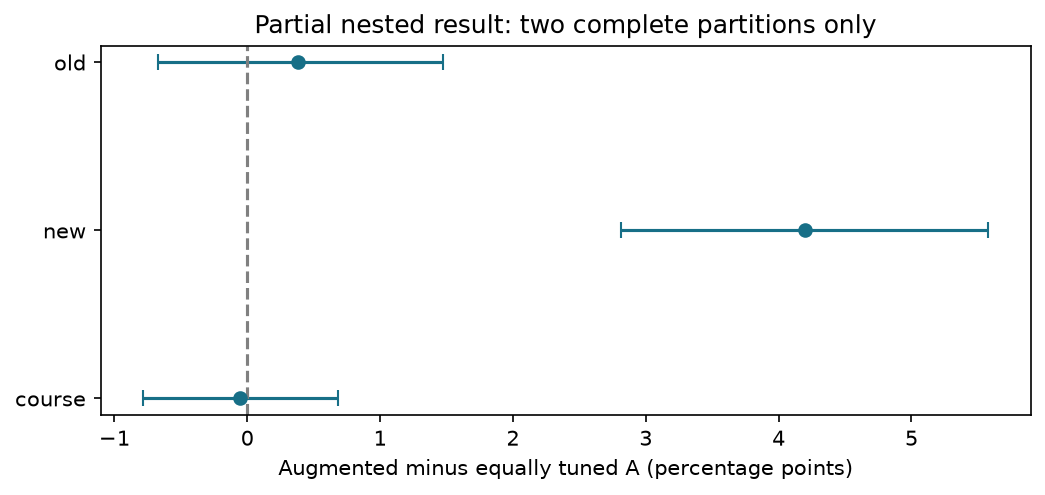

In [12]:
nested = load_result("latest_nested")
nested_table = pd.DataFrame([{"policy":r["policy"],**{
    panel+"_internal_pct":100*r[panel]["accuracy"] for panel in ["course","new","old"]}}
    for r in [latest["nested_tuned_course"],latest["nested_primary"]]])
display(nested_table)
delta_rows = [{"panel":panel,"delta_pp":100*r["delta"],
    "lower95_pp":100*r["ci95"][0],"upper95_pp":100*r["ci95"][1]}
    for panel,r in nested["primary_paired_deltas_vs_tuned_A"].items()]
deltas = pd.DataFrame(delta_rows)
display(deltas)
fig,ax = plt.subplots(figsize=(8,3.2))
ax.errorbar(deltas.delta_pp,deltas.panel,
    xerr=np.array([deltas.delta_pp-deltas.lower95_pp,deltas.upper95_pp-deltas.delta_pp]),
    fmt="o",capsize=4,color="#176f87")
ax.axvline(0,color="gray",linestyle="--")
ax.set(xlabel="Augmented minus equally tuned A (percentage points)",
       title="Partial nested result: two complete partitions only")
show_figure(fig)

### Locked settings, budget stop, and outstanding work

The final training-internal selection locked A with C=.25, threshold −.15, and augmented C
with C=1, threshold −.20. Selection-cache scores are not nested performance estimates and
are not development results. The internal gate failed even before the completeness check.
No final candidate model was exported; no new development evaluation was performed.
The measured total was 298.88928 CPU seconds of the 300-second budget (318.55841 wall seconds).
The missing outer fold is seed5192_outer2. This notebook does not resume that experiment.

**Outstanding, requiring a separately authorized scope/budget:** finish or explicitly accept the
incomplete nested study; refit/export the locked comparison if authorized; check export parity;
evaluate only equally tuned A and the one locked augmented candidate on the three approved dev
panels; apply the predeclared gate. Do not reselect a runner-up after seeing dev results.
Evidence for improvement on the sealed final test, a new leaderboard score, or a completed latest
development comparison is **unknown**. V3 remains the fast screening model; v4 remains the main
reference. The records do not support automatic promotion or an assertion of 90% accuracy.

In [ ]:
locked = load_result("latest_selection")
display(pd.DataFrame({k:locked[k] for k in ["tuned_course","augmented"]}).T)
cpu = load_result("latest_cpu")
incomplete = load_result("latest_incomplete")
status = {
    "fixed_outer_folds":latest["fixed_grid_complete_folds"],
    "nested_outer_folds":latest["nested_completed_folds"],
    "aggregated_complete_seed_partitions":latest["nested_aggregated_complete_partitions"],
    "CPU_seconds":cpu["total_measured_cpu_seconds"],
    "wall_seconds":cpu["total_measured_wall_seconds"],
    "final_model_exported":latest["final_model_exported"],
    "development_evaluated":latest["development_evaluated"],
    "internal_gate_passed":nested["internal_gate_passed"],
    "recommend_for_future_v4":latest["recommend_for_future_v4"]}
display(pd.Series(status,name="Archived status"))
assert status["fixed_outer_folds"] == 9 and status["nested_outer_folds"] == 8
assert status["aggregated_complete_seed_partitions"] == 2
assert not status["final_model_exported"] and not status["development_evaluated"]
expected = {f"seed{s}_outer{k}" for s in [5190,5191,5192] for k in range(3)}
print("Unfinished:",sorted(expected-set(incomplete["completed_outer_folds"])))
print("Data opened during this review:",sorted(READS))

## Reading and reproducing the historical evidence — Reproducibility and report wording

Every result table above is derived from its copied evidence/results JSON; package_manifest.json
maps it to the original handoff file. Links point to source text preserved for inspection.
The archived entry points are not notebook dependencies: some contain old absolute paths,
global CPU limits, mixed-metadata reads, or writes to historical model locations.
Keep this notebook's read-only evidence review separate from any new training run.
Report phrases such as “we observed on reused development,” “training-internal grouped CV,”
“not promoted,” and “budget-limited/incomplete” should be retained when summarizing these studies.